### 📊 Descrição das Variáveis do Dataset

- **income (numérico):** Renda anual do solicitante (em forma de decis). Varia entre [0.1, 0.9].
- **name_email_similarity (numérico):** Métrica de similaridade entre o e-mail e o nome do solicitante. Valores maiores indicam maior similaridade. Varia entre [0, 1].  
- **prev_address_months_count (numérico):** Número de meses no endereço anterior registrado do solicitante, isto é, sua residência anterior, se aplicável. Varia entre [-1, 380] meses (-1 indica valor ausente).  
- **current_address_months_count (numérico):** Meses no endereço atual registrado do solicitante. Varia entre [-1, 429] meses (-1 indica valor ausente).  
- **customer_age (numérico):** Idade do solicitante em anos, arredondada para a década. Varia entre [10, 90] anos.  
- **days_since_request (numérico):** Número de dias desde que a solicitação foi realizada. Varia entre [0, 79] dias.  
- **intended_balcon_amount (numérico):** Valor inicial transferido na solicitação. Varia entre [-16, 114] (valores negativos indicam ausentes).  
- **payment_type (categórico):** Tipo de plano de pagamento a crédito. 5 valores possíveis (anonimizados).  
- **zip_count_4w (numérico):** Número de solicitações no mesmo CEP nas últimas 4 semanas. Varia entre [1, 6830].  
- **velocity_6h (numérico):** Velocidade total de solicitações nas últimas 6 horas, isto é, média de solicitações por hora nesse período. Varia entre [-175, 16818].  
- **velocity_24h (numérico):** Velocidade total de solicitações nas últimas 24 horas, isto é, média de solicitações por hora nesse período. Varia entre [1297, 9586].  
- **velocity_4w (numérico):** Velocidade total de solicitações nas últimas 4 semanas, isto é, média de solicitações por hora nesse período. Varia entre [2825, 7020].  
- **bank_branch_count_8w (numérico):** Número total de solicitações na agência bancária selecionada nas últimas 8 semanas. Varia entre [0, 2404].  
- **date_of_birth_distinct_emails_4w (numérico):** Número de e-mails distintos para solicitantes com a mesma data de nascimento nas últimas 4 semanas. Varia entre [0, 39].  
- **employment_status (categórico):** Situação de emprego do solicitante. 7 valores possíveis (anonimizados).  
- **credit_risk_score (numérico):** Score interno de risco da aplicação. Varia entre [-191, 389].  
- **email_is_free (binário):** Domínio do e-mail da aplicação (gratuito ou pago).  
- **housing_status (categórico):** Situação residencial atual do solicitante. 7 valores possíveis (anonimizados).  
- **phone_home_valid (binário):** Validade do telefone residencial informado.  
- **phone_mobile_valid (binário):** Validade do telefone móvel informado.  
- **bank_months_count (numérico):** Tempo, em meses, da conta anterior (se existir). Varia entre [-1, 32] meses (-1 indica valor ausente).  
- **has_other_cards (binário):** Indica se o solicitante possui outros cartões do mesmo banco.  
- **proposed_credit_limit (numérico):** Limite de crédito proposto para o solicitante. Varia entre [200, 2000].  
- **foreign_request (binário):** Indica se o país de origem da solicitação é diferente do país do banco.  
- **source (categórico):** Origem online da solicitação. Pode ser navegador (INTERNET) ou aplicativo (TELEAPP).  
- **session_length_in_minutes (numérico):** Duração da sessão do usuário no site bancário, em minutos. Varia entre [-1, 107] minutos (-1 indica valor ausente).  
- **device_os (categórico):** Sistema operacional do dispositivo que fez a solicitação. Valores possíveis: Windows, macOS, Linux, X11 ou outros.  
- **keep_alive_session (binário):** Opção do usuário sobre manter a sessão ativa ao sair.  
- **device_distinct_emails (numérico):** Número de e-mails distintos utilizados no site bancário a partir do dispositivo nas últimas 8 semanas. Varia entre [-1, 2] (-1 indica valor ausente).  
- **device_fraud_count (numérico):** Número de solicitações fraudulentas associadas ao dispositivo. Varia entre [0, 1].  
- **month (numérico):** Mês em que a solicitação foi realizada. Varia entre [0, 7].  
- **fraud_bool (binário):** Indica se a solicitação é fraudulenta ou não.

## `1. Importing Libraries`

In [1]:
%pip install lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=c9bbadd3dfbb71ac17bbbad614d0a0ed1da9804882a1233e14ea678dc067edab
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [2]:
# Popular libraries
from typing import Dict, List, Tuple, Any, Union, Optional
from dataclasses import dataclass
import numpy as np
import pandas as pd
import pickle
from itertools import combinations
import os
import time
import glob
import ast
import re
# Graphs
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter, FuncFormatter
# Sklearn
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score
# Machine Learning
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.linear_model import Ridge
from scipy import stats
# Explainability Techniques
import shap
from lime.lime_tabular import LimeTabularExplainer
from lime.lime_base import LimeBase
# Statsmodels
from statsmodels.tools.tools import add_constant
from statsmodels.regression.linear_model import WLS

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Descobre o número de CPUs (lógicas)
total_cpus = os.cpu_count()
print(f"Número de CPUs: {total_cpus}")

Número de CPUs: 8


## `2. Settings`

In [6]:
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', None)

In [7]:
%matplotlib inline

In [8]:
# Define custom color palette
my_palette = sns.color_palette('husl', 2)
sns.set_style('whitegrid')

## `3. Functions`

In [9]:
def one_hot_encoding(df, categorical_feature):
    """
    Performs One-Hot Encoding on selected categorical features by creating
    binary indicator variables for each unique category.

    Args:
        df (pd.DataFrame):
            Input pandas DataFrame containing the original data.

        categorical_features (list of str):
            List of column names corresponding to categorical variables
            that will be transformed into dummy variables.

    Returns:
        pd.DataFrame:
            DataFrame containing the original data plus the newly created
            one-hot encoded columns.
    """
    for feature in categorical_feature:
        df[feature] = (
            df[feature]
            .str.strip()
            .str.lower()
            .replace(r'( |-)', '_', regex = True)
            .replace(r'[\W]', '', regex = True)
            .apply(lambda i: 'null' if (pd.isnull(i)) | (i == '') else i)
            .str.normalize('NFKD')
            .str.encode('ascii', errors='ignore')
            .apply(lambda i: i.decode('utf-8'))
        )

        freq_categories = (
            df[[feature]]
            .groupby(feature)
            .size()
            .reset_index(name='count')
            .sort_values(['count'], ascending=True)
        )

        categories = [c for c in freq_categories[feature]]
        df = df.assign(**{str(feature + '_' + c): df[feature].map(lambda i: 1 if i == c else 0) for c in categories})

    df = df.drop(categorical_feature, axis=1)

    return df

## `4. Load the data`

In [ ]:
pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Mestrado/Base.xls', sep=',', header=0)["month"].value_counts().sort_index()

,count
month,
0,132440
1,127620
2,136979
3,150936
4,127691
5,119323
6,108168
7,96843


In [ ]:
df_base = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Mestrado/Base.xls', sep=',', header=0)
df = df_base[df_base['month'].isin([0, 1, 2, 3, 4])].copy()

In [ ]:
# Get the number of rows and columns in the DataFrame
print('Number of rows:', df.shape[0])
print('Number of columns:', df.shape[1])

Number of rows: 675666
Number of columns: 32


## `5. Exploratory Data Analysis`

In [ ]:
# Display summary information about the DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 675666 entries, 0 to 675665
Data columns (total 32 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   fraud_bool                        675666 non-null  int64  
 1   income                            675666 non-null  float64
 2   name_email_similarity             675666 non-null  float64
 3   prev_address_months_count         675666 non-null  int64  
 4   current_address_months_count      675666 non-null  int64  
 5   customer_age                      675666 non-null  int64  
 6   days_since_request                675666 non-null  float64
 7   intended_balcon_amount            675666 non-null  float64
 8   payment_type                      675666 non-null  object 
 9   zip_count_4w                      675666 non-null  int64  
 10  velocity_6h                       675666 non-null  float64
 11  velocity_24h                      675666 non-null  float6

In [ ]:
# Get the number of unique values in each column of the DataFrame
df.nunique()

,0
fraud_bool,2
income,9
name_email_similarity,675117
prev_address_months_count,369
current_address_months_count,421
customer_age,9
days_since_request,670983
intended_balcon_amount,673389
payment_type,5
zip_count_4w,6300


In [ ]:
# Get a summary of statistical information for each numerical column in the DataFrame
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
fraud_bool,675666.0000,0.0100,0.0994,0.0000,0.0000,0.0000,0.0000,1.0000
income,675666.0000,0.5416,0.2925,0.1000,0.3000,0.6000,0.8000,0.9000
name_email_similarity,675666.0000,0.5034,0.2913,0.0000,0.2348,0.5063,0.7677,1.0000
prev_address_months_count,675666.0000,17.4525,45.0207,-1.0000,-1.0000,-1.0000,20.0000,377.0000
current_address_months_count,675666.0000,86.8164,90.8475,-1.0000,18.0000,51.0000,131.0000,425.0000
customer_age,675666.0000,33.6839,12.0954,10.0000,20.0000,30.0000,40.0000,90.0000
days_since_request,675666.0000,1.1406,5.5159,0.0000,0.0073,0.0154,0.0271,76.5815
intended_balcon_amount,675666.0000,9.1174,20.5288,-15.1674,-1.1598,-0.8027,9.9461,112.9569
zip_count_4w,675666.0000,1728.4069,1062.0951,1.0000,990.0000,1414.0000,2148.0000,6700.0000
velocity_6h,675666.0000,6394.3892,3039.9943,-130.4569,4191.8855,6274.6091,8341.3875,16715.5654


In [ ]:
# Get a summary of statistical information for each non-numerical column in the DataFrame
df.describe(include=['object', 'bool']).transpose()

,count,unique,top,freq
payment_type,675666,5,AB,235411
employment_status,675666,7,CA,480770
housing_status,675666,7,BC,262914
source,675666,2,INTERNET,670596
device_os,675666,5,linux,232252


### `5.1 Number of Instances by Target`

In [ ]:
#  Number of Transactions by Fraud Status
df_freq_fraud = pd.DataFrame(df['fraud_bool'].value_counts())
df_freq_fraud.reset_index(inplace=True)
print(df_freq_fraud)

   fraud_bool   count
0           0  668926
1           1    6740


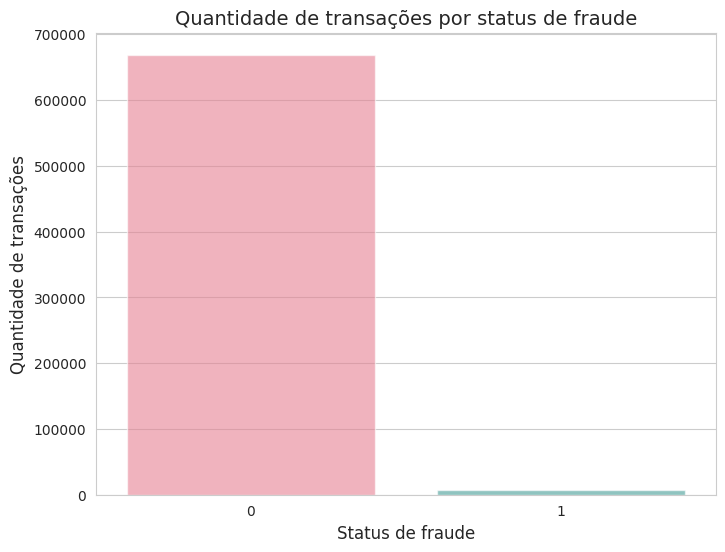

In [ ]:
# Set up plot
plt.figure(figsize=(8, 6))

# Create bar plot
sns.barplot(data=df_freq_fraud, x='fraud_bool', y='count', hue='fraud_bool', palette=my_palette, alpha=.6, legend=False)

# Customize labels and legend
plt.xlabel('Status de fraude', fontsize=12)
plt.ylabel('Quantidade de transações', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.title('Quantidade de transações por status de fraude', fontsize=14)

# Display plot
plt.show()

In [ ]:
df.groupby("month", as_index=False).agg(sum_target=("fraud_bool", "sum"), quantity=("fraud_bool", "count"),mean_target=("fraud_bool", "mean"))

,month,sum_target,quantity,mean_target
0,0,1500,132440,0.0113
1,1,1198,127620,0.0094
2,2,1198,136979,0.0087
3,3,1392,150936,0.0092
4,4,1452,127691,0.0114


### `5.2 Missing Values of Features by Target`

In [ ]:
# Initialize an empty DataFrame to hold the percentage of missing values for each feature
df_missing = pd.DataFrame()

# List of features to check for missing values
missing_features = [
    'prev_address_months_count',
    'current_address_months_count',
    'intended_balcon_amount',
    'bank_months_count',
    'session_length_in_minutes',
    'device_distinct_emails_8w'
]

# For each feature, replace -1 values with NaN, calculate the percentage of missing values
for feature in missing_features:
    df.loc[df[feature] < 0, feature] = np.nan

    freq_missing_feature = df.groupby('fraud_bool')[feature].apply(lambda x: round(x.isna().sum()/len(x) * 100, 2))
    df_missing[feature] = freq_missing_feature

In [ ]:
df.isnull().sum()

,0
fraud_bool,0
income,0
name_email_similarity,0
prev_address_months_count,469907
current_address_months_count,2827
customer_age,0
days_since_request,0
intended_balcon_amount,493751
payment_type,0
zip_count_4w,0


In [ ]:
df.isnull().sum() / df.shape[0] * 100

,0
fraud_bool,0.0000
income,0.0000
name_email_similarity,0.0000
prev_address_months_count,69.5472
current_address_months_count,0.4184
customer_age,0.0000
days_since_request,0.0000
intended_balcon_amount,73.0762
payment_type,0.0000
zip_count_4w,0.0000


In [ ]:
# Reshape the missing_vals DataFrame from wide to long format
df_missing = pd.DataFrame(df_missing.T.stack())

# Reset the index and rename the columns
df_missing.reset_index(inplace=True)
df_missing.rename(columns={'level_0': 'feature', 0: 'pc_missing'}, inplace=True)

print(df_missing)

                         feature  fraud_bool  pc_missing
0      prev_address_months_count           0     69.3300
1      prev_address_months_count           1     91.5400
2   current_address_months_count           0      0.4200
3   current_address_months_count           1      0.1200
4         intended_balcon_amount           0     72.9400
5         intended_balcon_amount           1     86.9900
6              bank_months_count           0     25.3700
7              bank_months_count           1     37.9500
8      session_length_in_minutes           0      0.1900
9      session_length_in_minutes           1      0.1500
10     device_distinct_emails_8w           0      0.0400
11     device_distinct_emails_8w           1      0.0400


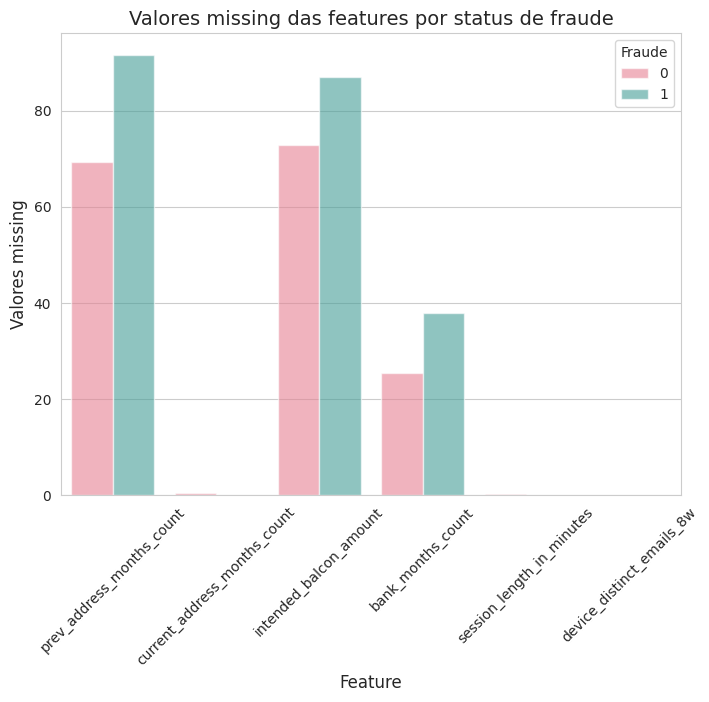

In [ ]:
# Set up plot
plt.figure(figsize=(8, 6))

# Create bar plot
sns.barplot(data=df_missing, x='feature', y='pc_missing', hue='fraud_bool', palette=my_palette, alpha=.6)

# Customize labels and legend
plt.xlabel('Feature', fontsize=12)
plt.ylabel('Valores missing', fontsize=12)
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)
plt.title('Valores missing das features por status de fraude', fontsize=14)
plt.legend(title="Fraude", fontsize=10)

# Display plot
plt.show()

In [ ]:
df.drop(['prev_address_months_count', 'intended_balcon_amount', 'bank_months_count'], axis=1, inplace=True)

### `5.3 Distribution of Numeric Features by Target`

In [ ]:
# Create a list of numeric features in the DataFrame df
numeric_features = [x for x in df.columns if df[x].dtypes != "object"]
numeric_features = [x for x in numeric_features if (df[x].nunique() > 2) & (x != "month")]

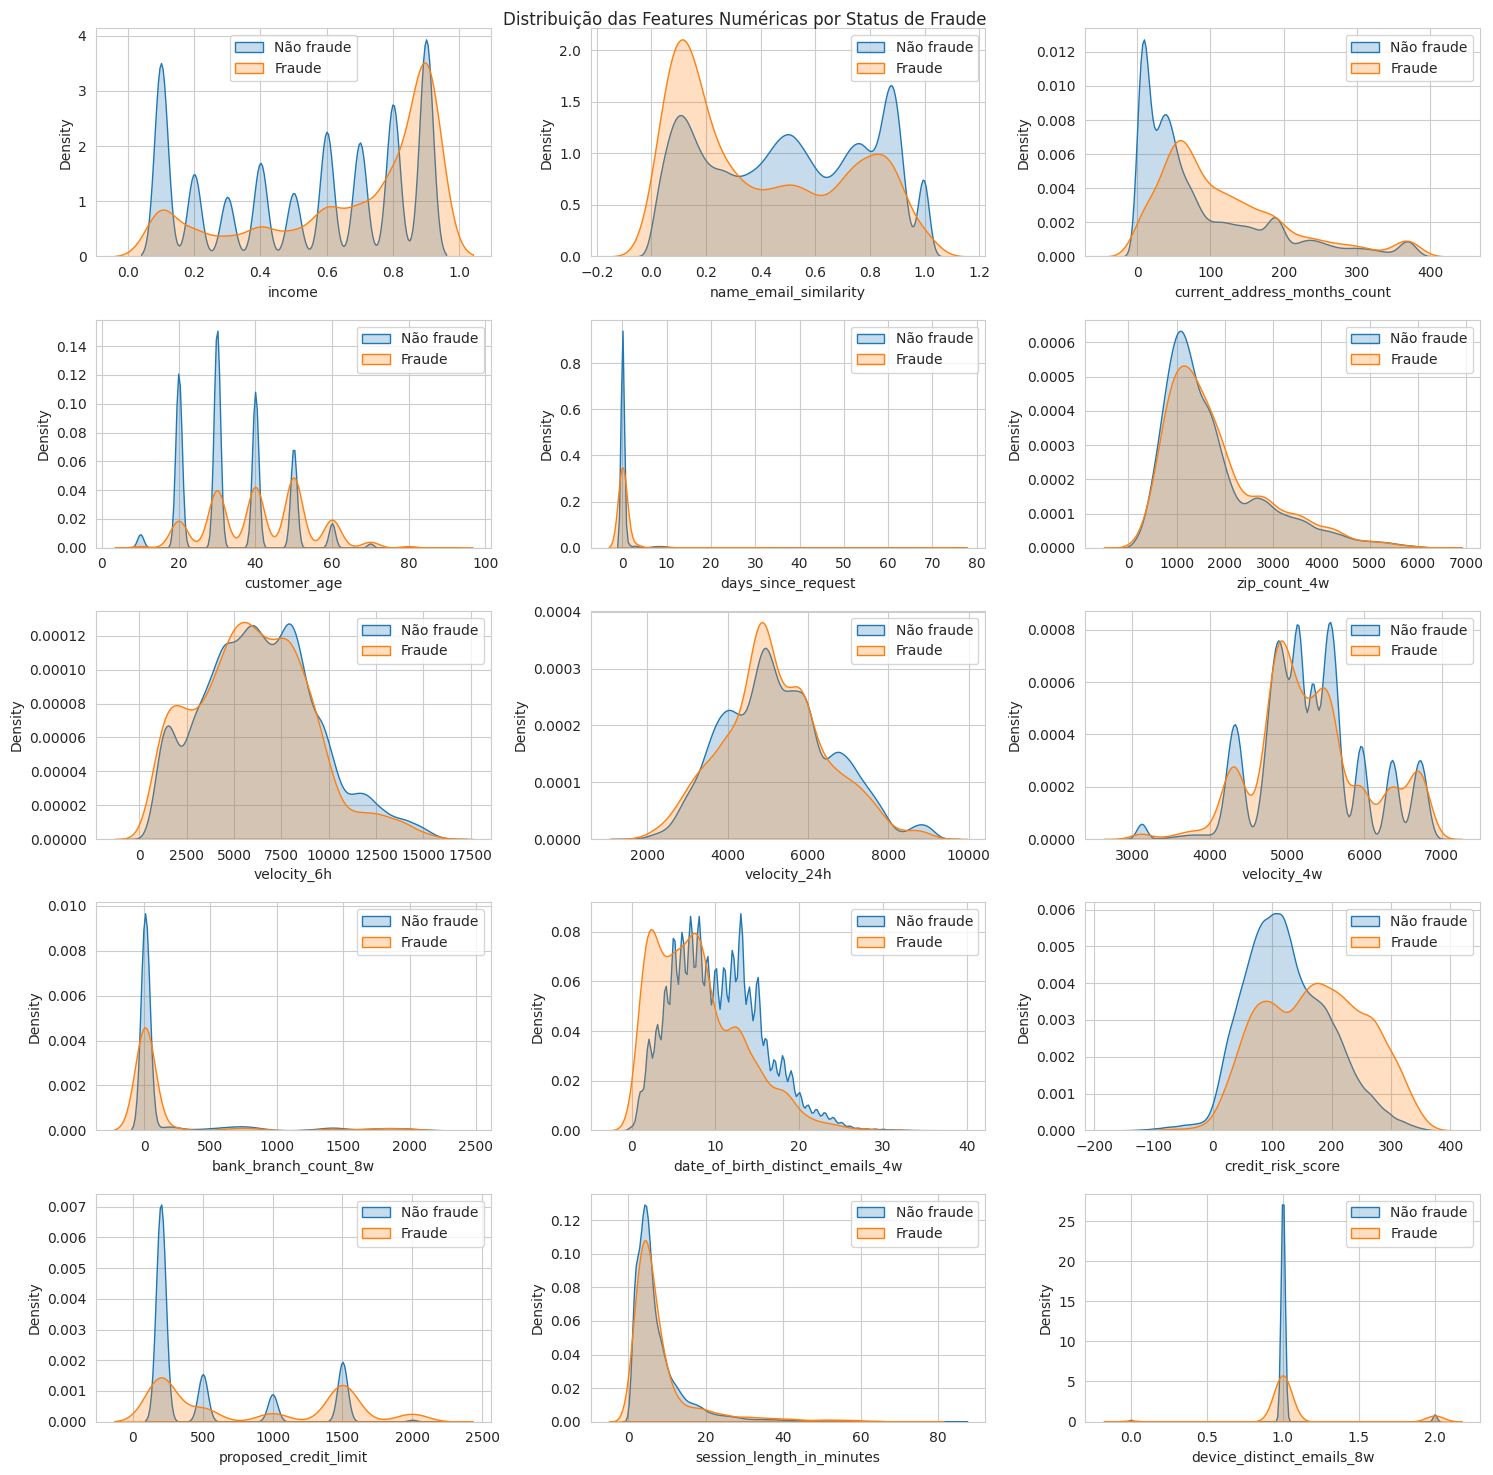

In [ ]:
# Create a grid of subplots
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(15, 15))

# Add a title to the figure
fig.suptitle('Distribuição das Features Numéricas por Status de Fraude')

# Loop through the numeric features and plot a kernel density plot for each feature
for i, feature in enumerate(numeric_features):
    ax = axes[i // 3][i % 3]
    sns.kdeplot(data=df[df['fraud_bool'] == 0][feature], fill=True, ax=ax, label='Não fraude')
    sns.kdeplot(data=df[df['fraud_bool'] == 1][feature], fill=True, ax=ax, label='Fraude')
    ax.set_xlabel(feature)
    ax.legend()

# Adjust the layout and display the plot
plt.tight_layout()
plt.show()

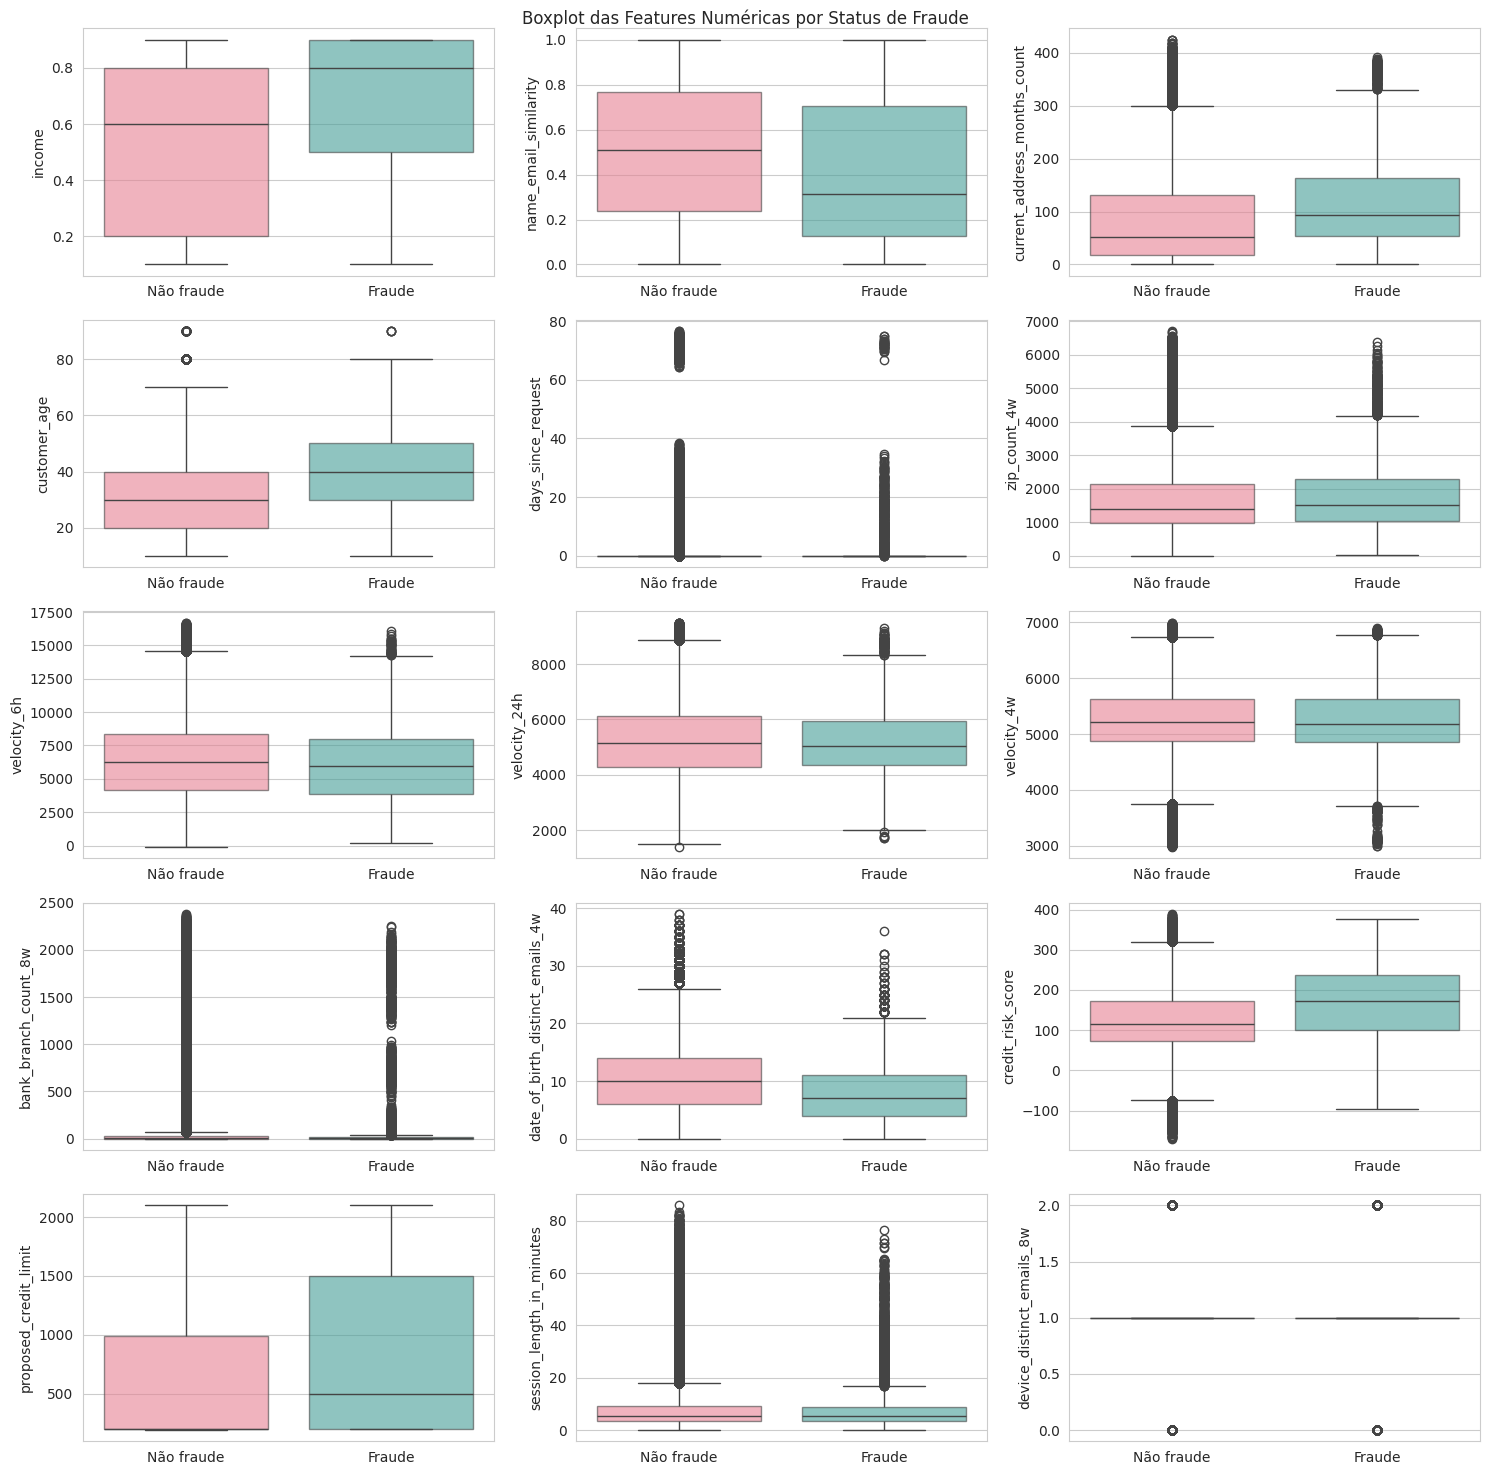

In [ ]:
# Create a grid of subplots
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(15, 15))

# Add a title to the figure
fig.suptitle('Boxplot das Features Numéricas por Status de Fraude')

# Loop through the numeric features and plot a box plot for each feature
for i, feature in enumerate(numeric_features):
    ax = axes[i // 3][i % 3]
    sns.boxplot(data=df, x='fraud_bool', y=feature, hue='fraud_bool', ax=ax, palette=my_palette, boxprops=dict(alpha=.6), legend=False)
    ax.set_xticks([0, 1], labels=['Não fraude', 'Fraude'])
    ax.set_xlabel('')
    ax.set_ylabel(feature)

# Adjust the layout and display the plot
plt.tight_layout()
plt.show()

### `5.4 Distribution of Categorical Features`

In [ ]:
# Create a list of categorical features in the DataFrame new_df whose data type is `object`
categorical_feature = [x for x in df.columns if df[x].dtypes == "object"]

In [ ]:
categorical_feature

['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']

In [ ]:
for col in categorical_feature:
    value_counts = df[col].value_counts(dropna=False)
    print(value_counts)
    print("=====================================")
    print()

payment_type
AB    235411
AA    181299
AC    171511
AD     87209
AE       236
Name: count, dtype: int64

employment_status
CA    480770
CB    102251
CF     30444
CC     27614
CD     19680
CE     14581
CG       326
Name: count, dtype: int64

housing_status
BC    262914
BB    171639
BE    115214
BA    110423
BD     14074
BF      1201
BG       201
Name: count, dtype: int64

source
INTERNET    670596
TELEAPP       5070
Name: count, dtype: int64

device_os
linux        232252
other        220215
windows      182429
macintosh     35809
x11            4961
Name: count, dtype: int64



In [ ]:
for col in categorical_feature:
    value_counts = df[col].value_counts(normalize=True, dropna=False) * 100
    value_counts = value_counts.round(2).astype(str) + '%'
    print(value_counts)
    print("=====================================")
    print()

payment_type
AB    34.84%
AA    26.83%
AC    25.38%
AD    12.91%
AE     0.03%
Name: proportion, dtype: object

employment_status
CA    71.15%
CB    15.13%
CF     4.51%
CC     4.09%
CD     2.91%
CE     2.16%
CG     0.05%
Name: proportion, dtype: object

housing_status
BC    38.91%
BB     25.4%
BE    17.05%
BA    16.34%
BD     2.08%
BF     0.18%
BG     0.03%
Name: proportion, dtype: object

source
INTERNET    99.25%
TELEAPP      0.75%
Name: proportion, dtype: object

device_os
linux        34.37%
other        32.59%
windows       27.0%
macintosh      5.3%
x11           0.73%
Name: proportion, dtype: object



In [ ]:
df.drop(columns=['source'], inplace=True)

## `6. Feature Engineering`

### `6.1 One-Hot Encoding for Categorical Features`

In [ ]:
# Create a list of categorical features in the DataFrame new_df whose data type is `object`
categorical_feature = [x for x in df.columns if df[x].dtypes == "object"]

In [ ]:
categorical_feature

['payment_type', 'employment_status', 'housing_status', 'device_os']

In [ ]:
df = one_hot_encoding(df, categorical_feature=categorical_feature)

In [ ]:
df.drop(columns=['payment_type_ae', 'employment_status_cg', 'housing_status_bg', 'housing_status_bf', 'device_os_x11'], inplace=True)

## `7. Feature Selection`

### `7.1 Removal of Features Without Variability`

In [ ]:
df_describe = df.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

In [ ]:
df_describe.loc[["1%", "99%"], df_describe.loc["1%"] == df_describe.loc["99%"]]

,fraud_bool,device_fraud_count
1%,0.0000,0.0000
99%,0.0000,0.0000


In [ ]:
no_variance_feature = ['device_fraud_count']
df.drop(columns=no_variance_feature, inplace=True)

### `7.2 Pearson Correlation to Measure Linear Relationships Between Features`

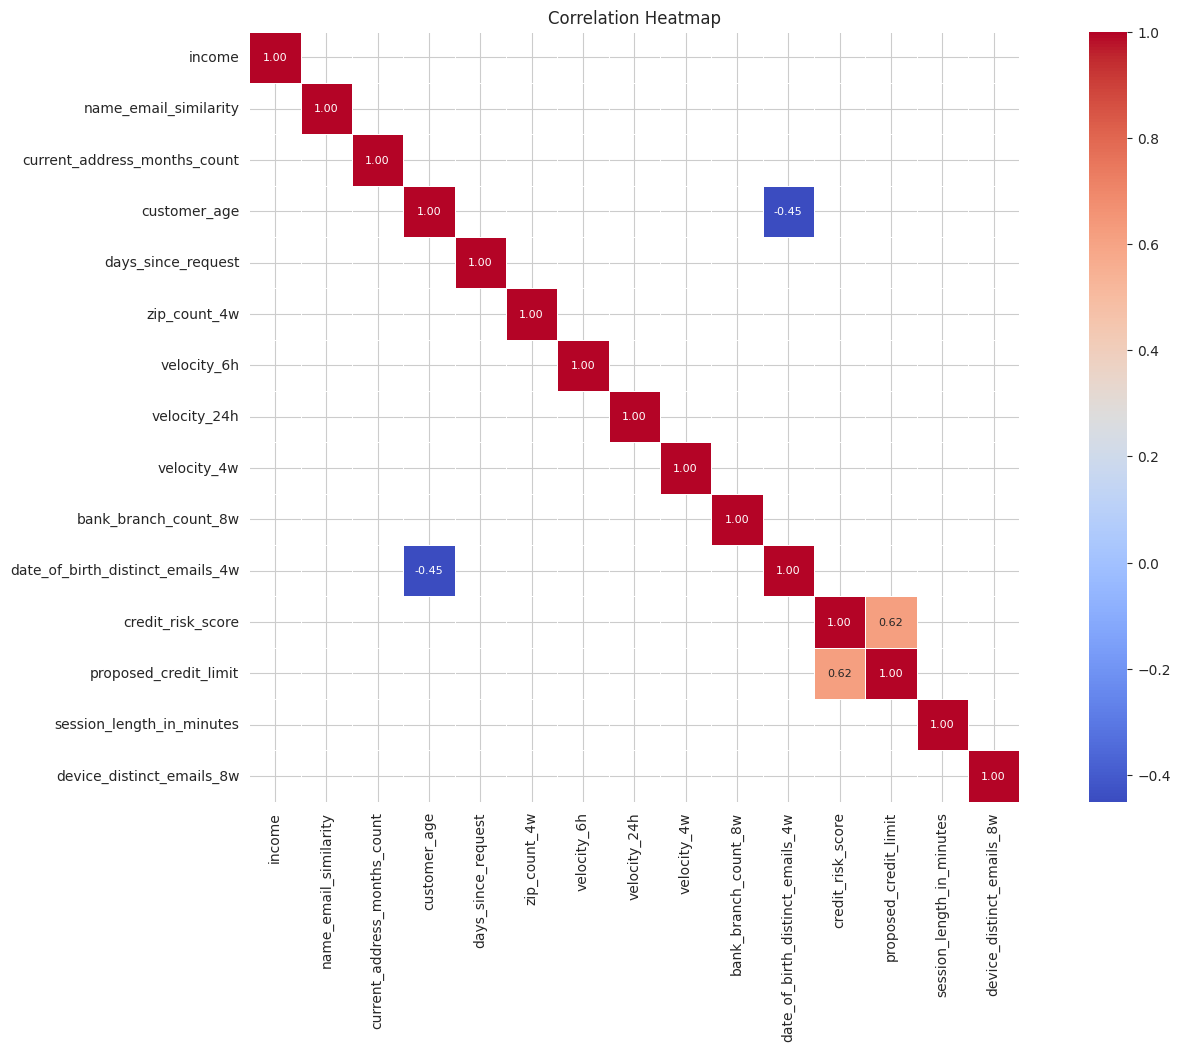

In [ ]:
# Compute correlation matrix
correlation_feature = [
    'income',
    'name_email_similarity',
    'current_address_months_count',
    'customer_age',
    'days_since_request',
    'zip_count_4w',
    'velocity_6h',
    'velocity_24h',
    'velocity_4w',
    'bank_branch_count_8w',
    'date_of_birth_distinct_emails_4w',
    'credit_risk_score',
    'proposed_credit_limit',
    'session_length_in_minutes',
    'device_distinct_emails_8w'
]

X_train_corr = df[correlation_feature].corr()

# Plot correlation matrix with annotated values
fig, ax = plt.subplots(figsize=(18, 10))
sns.heatmap(X_train_corr[(X_train_corr >= 0.4) | (X_train_corr <= -0.4)], annot=True, fmt=".2f", cmap='coolwarm', linewidths=.5, square=True, ax=ax, annot_kws={"fontsize": 8})
plt.title('Correlation Heatmap')
plt.show()

## `8. Setup Experimental: Desbalanceamento vs Estabilidade (LIME/SHAP)`

In [10]:
# ============================================================
# Utilidades
# ============================================================

def save_dataframe(df: pd.DataFrame, file_name: str, output_dir: str):
    """
    Salva um DataFrame em formato CSV.

    Args:
        df (pd.DataFrame): DataFrame que será salvo.
        file_name (str): Nome do arquivo.
        output_dir (str): Diretório onde o arquivo será salvo.
    """

    os.makedirs(output_dir, exist_ok=True)

    file_path = os.path.join(output_dir, f"{file_name}.csv")
    df.to_csv(file_path, index=False)

    print(f"Arquivo salvo: {file_path}")


def set_seed(seed: int = 1):
    """
    Cria um gerador de números aleatórios reprodutível.

    Args:
        seed (int, optional): Semente utilizada para inicializar o gerador. Default é 1.

    Returns:
        np.random.Generator: Gerador de números aleatórios do NumPy.
    """
    return np.random.default_rng(seed)


def ensure_dataframe(X):
    """
    Garante que a entrada seja um pandas.DataFrame.

    Se X já for um DataFrame, retorna uma cópia. Caso contrário, converte a entrada para DataFrame.

    Args:
        X: Estrutura contendo os atributos de entrada.

    Returns:
        pd.DataFrame: Dados convertidos para DataFrame.
    """
    if isinstance(X, pd.DataFrame):
        return X.copy()
    return pd.DataFrame(X)


def ensure_series(y):
    """
    Garante que a entrada seja uma pandas.Series.

    Se y já for uma Series, retorna uma cópia com o índice reiniciado. Caso contrário, converte a
    entrada para Series e reinicia o índice.

    Args:
        y: Vetor contendo a variável resposta.

    Returns:
        pd.Series: Variável resposta convertida para Series com índice sequencial.
    """
    if isinstance(y, pd.Series):
        return y.reset_index(drop=True).copy()
    return pd.Series(y).reset_index(drop=True)


def fillna_with_median(X_reference, X, columns):
    """
    Preenche os valores ausentes das colunas especificadas utilizando as medianas calculadas
    a partir de um DataFrame de referência.

    As medianas são calculadas individualmente para cada coluna do DataFrame de referência
    e aplicadas ao DataFrame de destino. Uma cópia é criada para evitar alterações nos dados originais.

    Args:
        X_reference (pd.DataFrame): DataFrame utilizado para calcular as medianas das variáveis.
        X (pd.DataFrame): DataFrame cujos valores ausentes serão preenchidos.
        columns (list[str]): Lista com os nomes das colunas que serão tratadas.

    Returns:
        pd.DataFrame: Cópia do DataFrame X com os valores ausentes preenchidos pelas medianas
            calculadas a partir de X_reference.
    """
    X_new = X.copy()

    for col in columns:
        X_new[col] = X_new[col].fillna(X_reference[col].median())

    return X_new

In [11]:
# ============================================================
# Seleção do conjunto fixo de instâncias para explicação
# ============================================================

def sample_fixed_explain_set(
    X: pd.DataFrame,
    y: pd.Series,
    n_pos: int,
    n_neg: int,
    seed: int = 1
) -> Tuple[pd.DataFrame, pd.Series, np.ndarray]:
    """
    Seleciona um conjunto fixo de instâncias que serão utilizadas para a geração das explicações.

    A função realiza uma amostragem aleatória sem reposição, escolhendo separadamente instâncias da
    classe positiva e da classe negativa. As instâncias selecionadas permanecem fixas ao longo de
    todo o experimento, garantindo que todos os cenários sejam avaliados sobre o mesmo conjunto de
    instâncias.

    Args:
        X (pd.DataFrame): Conjunto de atributos.
        y (pd.Series): Variável resposta binária.
        n_pos (int): Número de observações da classe positiva a serem selecionadas.
        n_neg (int): Número de observações da classe negativa a serem selecionadas.
        seed (int, optional): Semente utilizada para reprodução da amostragem. Default é 1.

    Returns:
        Tuple[pd.DataFrame, pd.Series, np.ndarray]:
            - X (pd.DataFrame): Observações selecionadas.
            - y (pd.Series): Classes correspondentes às observações selecionadas.
            - idx (np.ndarray): Índices (posições) das observações selecionadas no conjunto original.
    """
    rng = set_seed(seed)

    y_np = y.to_numpy()

    pos_idx = np.where(y_np == 1)[0]
    neg_idx = np.where(y_np == 0)[0]

    if len(pos_idx) < n_pos:
        raise ValueError(f"Poucos positivos: precisa {n_pos}, tem {len(pos_idx)}")

    if len(neg_idx) < n_neg:
        raise ValueError(f"Poucos negativos: precisa {n_neg}, tem {len(neg_idx)}")

    chosen_pos = rng.choice(pos_idx, size=n_pos, replace=False)
    chosen_neg = rng.choice(neg_idx, size=n_neg, replace=False)

    idx = np.concatenate([chosen_pos, chosen_neg])
    rng.shuffle(idx)

    return (
        X.iloc[idx].reset_index(drop=True),
        y.iloc[idx].reset_index(drop=True),
        idx
    )

In [12]:
# ============================================================
# Amostras com diferentes taxas de fraude
# ============================================================

def sample_imbalanced_set(
    X: pd.DataFrame,
    y: pd.Series,
    total_size: int,
    target_rate: float,
    seed: int = 1
) -> Tuple[pd.DataFrame, pd.Series, Dict[str, Any]]:

    """
    Cria uma amostra aleatória sem reposição com tamanho fixo e proporção desejada da classe positiva.

    A amostragem é realizada separadamente para as classes positiva (y = 1) e negativa (y = 0),
    garantindo que a taxa de eventos da amostra seja aproximadamente igual à especificada em
    ``target_rate``. Caso o número de observações disponíveis em alguma das classes seja insuficiente,
    uma exceção é lançada.

    Args:
        X (pd.DataFrame): Conjunto de atributos.
        y (pd.Series): Variável resposta binária.
        total_size (int): Número total de observações da amostra.
        target_rate (float): Proporção desejada da classe positiva, devendo estar no intervalo [0, 1].
        seed (int, optional): Semente utilizada para reprodução da amostragem. Default é 1.

    Returns:
        Tuple[pd.DataFrame, pd.Series, Dict[str, Any]]:
            - X_sample (pd.DataFrame): Amostra dos atributos.
            - y_sample (pd.Series): Classes correspondentes à amostra.
            - info (Dict[str, Any]): Dicionário contendo informações sobre a amostragem, incluindo:
                * target_rate_requested: taxa de eventos solicitada;
                * target_rate_actual: taxa de eventos obtida;
                * target_rate_pct: taxa de eventos em formato percentual;
                * n_targets: número de observações da classe positiva;
                * n_non_targets: número de observações da classe negativa;
                * total: tamanho total da amostra;
                * sample_idx: índices (posições) das observações selecionadas no conjunto original.
    """
    if len(X) != len(y):
        raise ValueError(
            f"X e y possuem tamanhos diferentes: len(X)={len(X)} e len(y)={len(y)}."
        )

    if total_size <= 0:
        raise ValueError("total_size deve ser maior que zero.")

    if not 0 <= target_rate <= 1:
        raise ValueError("target_rate deve estar entre 0 e 1.")

    rng = set_seed(seed)

    y_np = y.to_numpy()

    pos_idx = np.where(y_np == 1)[0]
    neg_idx = np.where(y_np == 0)[0]

    n_pos = int(round(total_size * target_rate))
    n_neg = total_size - n_pos

    if n_pos > len(pos_idx):
        raise ValueError(
            f"target_rate={target_rate:.4f}: precisa de {n_pos} positivos, "
            f"mas existem apenas {len(pos_idx)}."
        )

    if n_neg > len(neg_idx):
        raise ValueError(
            f"target_rate={target_rate:.4f}: precisa de {n_neg} negativos, "
            f"mas existem apenas {len(neg_idx)}."
        )

    chosen_pos = rng.choice(pos_idx, size=n_pos, replace=False)
    chosen_neg = rng.choice(neg_idx, size=n_neg, replace=False)

    idx = np.concatenate([chosen_pos, chosen_neg])
    rng.shuffle(idx)

    X_sample = X.iloc[idx].reset_index(drop=True)
    y_sample = y.iloc[idx].reset_index(drop=True)

    actual_rate = float(y_sample.mean())

    info = {
        "target_rate_requested": target_rate,
        "target_rate_actual": actual_rate,
        "target_rate_pct": f"{actual_rate * 100:.1f}%",
        "n_targets": n_pos,
        "n_non_targets": n_neg,
        "total": len(y_sample),
        "sample_idx": idx
    }

    return X_sample, y_sample, info

In [13]:
# ============================================================
# Métrica de seleção do modelo
# ============================================================

def ks(y_true, y_prob):
    """
    Calcula a estatística de Kolmogorov-Smirnov (KS) para um modelo de classificação binária.

    A estatística KS corresponde à máxima diferença entre as distribuições acumuladas das
    probabilidades previstas para as classes positiva (y = 1) e negativa (y = 0). Quanto maior
    o valor de KS, maior é a capacidade do modelo em separar as duas classes.

    Args:
        y_true (array-like): Valores verdadeiros da variável resposta binária.
        y_prob (array-like): Probabilidades previstas para a classe positiva.

    Returns:
        ks (float): Valor da estatística KS.
    """

    df = pd.DataFrame({"y_true": y_true, "y_prob": y_prob})

    positives = df.loc[df["y_true"] == 1]["y_prob"]
    negatives = df.loc[df["y_true"] == 0]["y_prob"]

    ks = stats.ks_2samp(positives, negatives).statistic

    return ks


def evaluate_model(y_true, y_prob):
    """
    Calcula métricas de desempenho de um modelo de classificação binária.

    Atualmente, a função calcula:
        - AUC: Área sob a Curva ROC.
        - KS: Estatística de Kolmogorov-Smirnov.

    Args:
        y_true (array-like): Valores verdadeiros da variável resposta binária.
        y_prob (array-like): Probabilidades previstas para a classe positiva.

    Returns:
        dict: Dicionário contendo todas as métricas calculadas.
    """

    return roc_auc_score(y_true, y_prob), ks(y_true, y_prob)

In [14]:
# ============================================================
# Treinamento do modelo + Grid Search
# ============================================================
def tune_model(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    model_type: str,
    seed: int = 1,
    scoring_metric: str = "roc_auc",
    n_splits: int = 5,
    n_jobs: int = -1
) -> Tuple[Any, Dict[str, Any], float]:
    """
    Ajusta um modelo de classificação utilizando Grid Search com validação cruzada estratificada.

    Modelos disponíveis:
        - "rf": Random Forest
        - "lgbm": LightGBM

    Args:
        X_train (pd.DataFrame): Conjunto de atributos utilizado no treinamento.
        y_train (pd.Series): Variável resposta do conjunto de treinamento.
        model_type (str): Algoritmo utilizado no treinamento. Opções disponíveis: "rf" e "lgbm"
        seed (int, optional): Semente utilizada para garantir a reprodutibilidade. Default é 1.
        scoring_metric (str, optional): Métrica utilizada para selecionar o melhor modelo durante a validação cruzada. Default é "roc_auc".
        n_splits (int, optional): Número de partições da validação cruzada estratificada. Default é 5.
        n_jobs (int, optional): Número de processos utilizados pelo GridSearchCV. Utilize -1 para usar todos os núcleos disponíveis. Default é -1.

    Returns:
        Tuple[Any, Dict[str, Any], float]:
            - best_estimator: modelo ajustado com os melhores hiperparâmetros.
            - best_params: melhores hiperparâmetros encontrados.
            - best_score: melhor valor da métrica de validação cruzada.
    """
    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    if model_type == "rf":

        model = RandomForestClassifier(
            criterion="gini",
            min_samples_split=10,
            min_samples_leaf=5,
            n_jobs=1,
            random_state=seed
        )

        param_grid = {
            "n_estimators": [100, 150, 200],
            "max_depth": [5, 10, 15]
        }

    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_type == "lgbm":

        model = LGBMClassifier(
            objective="binary",
            random_state=seed,
            n_jobs=1,
            verbosity=-1
        )

        param_grid = {
            "n_estimators": [100, 150, 200],
            "max_depth": [5, 10, 15],
            "learning_rate": [0.05, 0.10]
        }

    else:
        raise ValueError(
            "model_type deve ser 'rf' ou 'lgbm'."
        )

    # --------------------------------------------------------
    # Validação cruzada
    # --------------------------------------------------------

    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    # --------------------------------------------------------
    # Grid Search
    # --------------------------------------------------------

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring=scoring_metric,
        cv=cv,
        n_jobs=n_jobs,
        verbose=0,
        refit=True
    )

    # --------------------------------------------------------
    # Treinamento
    # --------------------------------------------------------

    grid_search.fit(X_train, y_train)

    # --------------------------------------------------------
    # Resultados
    # --------------------------------------------------------

    return (
        grid_search.best_estimator_,
        grid_search.best_params_,
        grid_search.best_score_
    )

In [15]:
# ============================================================
# Explicações com SHAP
# ============================================================

def calculate_local_shap(model, X_explain: pd.DataFrame, class_index: int=1):
    """
    Calcula os valores SHAP locais para um conjunto de instâncias.

    A função utiliza o TreeExplainer para estimar a contribuição de cada variável na predição individual
    de cada instância em ``X_explain``.

    Args:
        model: Modelo baseado em árvores previamente treinado, como Random Forest, XGBoost ou LightGBM.
        X_explain (pd.DataFrame): Instâncias para as quais serão calculados os valores SHAP.
        class_index (int, optional): Índice da classe cujos valores SHAP serão retornados em problemas de
            classificação binária. Default é 1 (classe positiva).

    Returns:
        df_shap (pd.DataFrame): DataFrame em que cada linha corresponde a uma instância de ``X_explain`` e cada coluna
        corresponde a uma variável explicativa. Os valores representam os valores SHAP locais de cada variável
        para cada instância.
    """
    explainer = shap.TreeExplainer(model)
    shap_values_obj = explainer(X_explain)
    shap_values = shap_values_obj.values

    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, 1]

    shap_abs = np.abs(shap_values)

    df_shap = pd.DataFrame(shap_abs, columns=X_explain.columns, index=X_explain.index)

    return df_shap

In [16]:
# ============================================================
# Sequential Rank Agreement (SRA)
# ============================================================

def sequential_rank_agreement(importance_values, depths=None):
    """
    Calcula o Sequential Rank Agreement (SRA) diretamente a partir dos valores de importância.

    Args:
        importance_values (pd.DataFrame): Cada linha representa uma instância, cada coluna representa uma feature
            e os valores são os valores de importância das features.
        depths (list, optional): Lista com as profundidades desejadas. Exemplo: [1, 3, 5, 10].
            Se None, calcula todas as profundidades possíveis.

        Exemplo:
                         A       B       C       D
        instancia_1    0.40   -0.10    0.25    0.05
        instancia_2    0.35   -0.20    0.15    0.08
        instancia_3    0.30   -0.05    0.28    0.10

    Returns:
        pd.DataFrame: SRA para cada profundidade d.
    """
    # ---------------------------------------------------------
    # 1. Converter SHAP values em rankings
    # ---------------------------------------------------------

    rankings = []

    for _, row in importance_values.iterrows():

        # Importância = |SHAP|
        importance = row.abs()

        # Ordenar do maior SHAP absoluto para o menor
        ranking = importance.sort_values(ascending=False).index.tolist()
        rankings.append(ranking)

    # ---------------------------------------------------------
    # 2. Número de rankings
    # ---------------------------------------------------------

    L = len(rankings)

    if L < 2:
        raise ValueError("São necessários pelo menos dois rankings.")

    # ---------------------------------------------------------
    # 3. Criar posição de cada feature em cada ranking
    # ---------------------------------------------------------

    rank_maps = []

    for ranking in rankings:

        rank_map = {feature: position for position, feature in enumerate(ranking, start=1)}

        rank_maps.append(rank_map)

    # Todas as features
    all_features = list(importance_values.columns)

    # ---------------------------------------------------------
    # 4. Calcular A(F_p)
    #
    #             L
    #            Σ (R_i(F_p) - R_bar(F_p))²
    #           i=1
    # A(F_p) = -----------------------------
    #                     L - 1
    #
    # Ou seja: variância das posições da feature
    # =========================================================

    agreement = {}

    for feature in all_features:

        ranks = np.array([rank_map[feature] for rank_map in rank_maps])

        mean_rank = ranks.mean()

        A_fp = np.sum((ranks - mean_rank) ** 2) / (L - 1)

        agreement[feature] = A_fp

    # ---------------------------------------------------------
    # 5. Calcular SRA para cada profundidade d
    # ---------------------------------------------------------
    max_depth = len(all_features)

    if depths is None:
        # Se não passar nada, usa todas
        depths = list(range(1, max_depth + 1))
    else:
        # Garante que seja uma lista
        depths = list(depths)

        # Verificar profundidades inválidas
        invalid_depths = [d for d in depths if d < 1 or d > max_depth]

        if invalid_depths:
            raise ValueError(
                f"Profundidades inválidas: {invalid_depths}. "
                f"Devem estar entre 1 e {max_depth}."
            )

    results = []

    for d in depths:

        # União das features que aparecem nos primeiros d lugares dos rankings
        S_d = set()

        for ranking in rankings:
            S_d.update(ranking[:d])

        S_d = sorted(S_d)

        # ---------------------------------------------------------
        # SRA(d)
        #             1
        # SRA(d) = ------- Σ A(F_p)
        #           |S_d|
        # F_p ∈ S_d
        # ---------------------------------------------------------

        sra = np.mean([agreement[feature] for feature in S_d])

        results.append({
            "depth": d,
            "n_features": len(S_d),
            "features": sorted(S_d),
            "sra": sra
        })

    return pd.DataFrame(results)

In [17]:
# ============================================================
# Jaccard Index
# ============================================================

def jaccard_stability(importance_values, depths=None):
    """
    Calcula a estabilidade da seleção das variáveis por meio do Índice de Jaccard, considerando diferentes
    profundidades de seleção.

    Args:
        importance_values (pd.DataFrame): Cada linha representa uma instância, cada coluna representa uma feature
            e os valores são os valores de importância das features.
        depths (list, optional): Lista com as profundidades desejadas. Exemplo: [1, 3, 5, 10].
            Se None, calcula todas as profundidades possíveis.

    Returns:
        pd.DataFrame: Índice de Jaccard para cada profundidade d.
    """
    results = []

    for d in depths:

        selected_features = []

        for _, row in importance_values.iterrows():

            top_d = set(row.abs().nlargest(d).index)
            selected_features.append(top_d)

        jaccard_values = [len(A & B) / len(A | B) for A, B in combinations(selected_features, 2)]

        features = set().union(*selected_features)

        results.append({
            "depth": d,
            "n_features": len(features),
            "features": sorted(features),
            "jaccard": np.mean(jaccard_values)
        })

    return pd.DataFrame(results)

In [18]:
# ============================================================
# Coefficient of Variation (CV)
# ============================================================
def coefficient_of_variation(df, feature_col="feature", importance_col="importance"):
    """
    Calcula o Coeficiente de Variação (CV) para cada feature.

    Args:
        df (pd.DataFrame): DataFrame contendo os valores de importância.
        feature_col (str): Nome da coluna que identifica a feature.
        importance_col (str): Nome da coluna contendo o valor de importância.

    Returns:
        cv_global (float): Coeficiente de Variação (CV) médio entre as features.
    """

    df_stats_by_feature = (
        df
        .groupby(feature_col)[importance_col]
        .agg(mean_importance="mean", std_importance="std", n="count")
        .reset_index()
    )

    # CV = desvio-padrão / média
    df_stats_by_feature["cv"] = (df_stats_by_feature["std_importance"] / df_stats_by_feature["mean_importance"])

    cv_global = df_stats_by_feature["cv"].mean()

    return cv_global

In [19]:
# ============================================================
# Índices de Estabilidade do LIME
# ============================================================

"""Este script contém um conjunto de funções utilitárias que auxiliam no cálculo dos índices de estabilidade do LIME."""

class LocalModelError(Exception):
    """Exceção personalizada lançada quando o modelo não é uma Regressão Ridge Ponderada"""
    pass


def compute_WLS_stdevs(X, Y, weights, alpha):
    """
    Função para calcular os desvios-padrão dos coeficientes da Regressão Ridge Ponderada.

    Args:
        X: conjunto de dados contendo as variáveis explicativas.
        Y: vetor da variável resposta.
        weights: vetor de pesos (um para cada observação do conjunto de dados X).
        alpha: parâmetro de regularização.

    Returns:
        stdevs_beta: lista contendo os desvios-padrão dos coeficientes.
    """
    # Build Weighted Regression (WLS) model
    X_enh = add_constant(X)
    wls_model = WLS(Y, X_enh, weights=weights)
    results = wls_model.fit()
    errors_wls_weighted = results.wresid

    # Estimate of the sigma squared quantity
    sigma2 = np.dot(errors_wls_weighted.T, errors_wls_weighted) / (X.shape[0] - X.shape[1])
    weights_matr = np.diag(weights)  # reformulate weights as diagonal matrix

    # Standard deviations of the coefficients
    partial_ = np.linalg.inv(np.linalg.multi_dot([X.T, weights_matr, X]) +
                             alpha * np.diag([1, ] * X.shape[1]))
    variances_beta_matrix = sigma2 * np.linalg.multi_dot(
        [partial_, X.T, weights_matr, X, partial_.T])
    variances_beta = np.diag(variances_beta_matrix)
    stdevs_beta = list(np.sqrt(variances_beta))

    return stdevs_beta


def refactor_confints_todict(means, st_devs, feat_names):
    """
    Organiza as médias e os intervalos de confiança em um dicionário.

    Args:
        means: lista das médias dos coeficientes da Regressão Ridge Ponderada (WRR).
        st_devs: lista dos desvios-padrão dos coeficientes da WRR.
        feat_names: lista dos nomes das variáveis associados aos coeficientes.

    Returns:
        conf_int: dicionário em que:
            chave = nome da variável.
            valor = intervalo de confiança da variável (limite superior, limite inferior).
    """
    conf_int = {}
    for name, mean, stdev in zip(feat_names, means, st_devs):
        conf_int[name] = [mean - 1.96 * stdev, mean + 1.96 * stdev]
    return conf_int


def compare_confints(confidence_intervals, index_verbose=False):
    """
    Função para comparar os intervalos de confiança obtidos por diferentes modelos de Regressão Ridge
    Ponderada (WRR), construídos com o mesmo número de variáveis (possivelmente diferentes entre si).

    Função principal do pacote: calcula os dois índices complementares de estabilidade, CSI e VSI.

    Args:
        confidence_intervals: lista de dicionários. Cada dicionário corresponde à saída da função confint.
        index_verbose: controla o nível de detalhamento dos índices de estabilidade. Quando definido como
        True, fornece informações sobre os valores parciais relacionados à estabilidade.

    Returns:
        csi: índice de Estabilidade dos Coeficientes (Coefficients Stability Index).
        vsi: índice de Estabilidade das Variáveis (Variables Stability Index).
    """
    n_features = len(confidence_intervals[0].keys())
    features_limes = []

    for conf_int in confidence_intervals:
        features_limes.append(conf_int.keys())

    unique_features = list(set([l for ll in features_limes for l in ll]))

    # Calculate CSI
    overlapping_tot = []

    for feat in unique_features:
        conf_int_feat = []
        for conf_int in confidence_intervals:
            if conf_int.get(feat):
                conf_int_feat.append(conf_int.get(feat))

        if len(conf_int_feat) < 2:
            pass
        else:
            overlapping = []
            for pair_intervals in combinations(conf_int_feat, 2):
                i1, i2 = pair_intervals
                is_overlap = True if (i1[0] < i2[1] and i2[0] < i1[1]) else False
                overlapping.append(is_overlap)
            frac_overlapping = round(sum(overlapping) / len(overlapping) * 100, 2)
            overlapping_tot.append(frac_overlapping)
            if index_verbose:
                print("""Percentage of overlapping confidence intervals, variable {}: {}%\n""".format(
                    feat, frac_overlapping))

    csi = round(np.mean(overlapping_tot), 2)

    # Calculate VSI
    same_vars = 0
    n_combs = 0

    for pair_vars in combinations(features_limes, 2):
        var1, var2 = pair_vars
        same_vars += len(set(var1) & set(var2))
        n_combs += 1

    vsi = round(same_vars / (n_combs * n_features) * 100, 2)

    if index_verbose:
        print("""Percentage same variables across repeated LIME calls: {}%\n""".format(vsi))

    return csi, vsi

"""
Script principal, no qual as classes do LIME são redefinidas para permitir o cálculo dos índices de estabilidade.

Para isso, a classe original LimeTabularExplainer é sobrescrita pela classe LimeTabularExplainerOvr, que permite a mesma
utilização da implementação original do LIME.

Além disso, contém o método check_stability, responsável pelo cálculo dos índices CSI e VSI.
"""

class LimeBaseOvr(LimeBase):
    """Sobrescrita da classe original LimeBase, localizada no módulo lime_base"""

    def __init__(self, kernel_fn, verbose=False, random_state=None):
        """Herda da classe original LimeBase"""
        super(LimeBaseOvr, self).__init__(kernel_fn, verbose, random_state)

    def explain_instance_with_data(
        self,
        neighborhood_data,
        neighborhood_labels,
        distances,
        label,
        num_features,
        feature_selection='auto',
        model_regressor=None
    ):
        """
        Sobrescrita do método original explain_instance_with_data, realizada para permitir o acesso ao conjunto de
        dados gerado e a outras quantidades importantes para o cálculo dos intervalos de confiança e para a avaliação
        da estabilidade.

        Documentação original da função: Recebe dados perturbados, rótulos e distâncias e retorna uma explicação.

        Args:
            neighborhood_data: dados perturbados, matriz bidimensional. Assume-se que o primeiro elemento corresponde à observação original.
            neighborhood_labels: rótulos correspondentes aos dados perturbados. Deve conter tantas colunas quanto o número de classes possíveis.
            distances: distâncias em relação à observação original.
            label: classe para a qual se deseja obter uma explicação.
            num_features: número máximo de variáveis na explicação.
            feature_selection: método utilizado para selecionar num_features. As opções são:
                'forward_selection': adiciona iterativamente variáveis ao modelo. Apresenta alto custo computacional quando num_features é elevado.
                'highest_weights': seleciona as variáveis que apresentam os maiores produtos entre o valor absoluto do peso e o valor da variável
                    na observação original, considerando um modelo ajustado com todas as variáveis.
                'lasso_path': seleciona as variáveis com base no caminho de regularização do Lasso.
                'none': utiliza todas as variáveis, ignorando num_features.
                'auto': utiliza 'forward_selection' quando num_features <= 6 e 'highest_weights' caso contrário.
            model_regressor: regressor do scikit-learn utilizado na explicação. Se None, utiliza a Regressão Ridge como padrão. O regressor
                deve possuir o atributo model_regressor.coef_ e aceitar o parâmetro 'sample_weight' no método model_regressor.fit().

        Returns:
            (intercept, exp, score, local_pred):
                intercept: valor do intercepto, do tipo float.
                exp: lista ordenada de tuplas, em que cada tupla (x, y) corresponde ao identificador da variável (x) e ao seu coeficiente local (y).
                    A lista é ordenada pelo valor absoluto de y, em ordem decrescente.
                score: valor de R² da explicação retornada.
                local_pred: previsão realizada pelo modelo explicativo para a observação original.
        """
        weights = self.kernel_fn(distances)
        labels_column = neighborhood_labels[:, label]
        used_features = self.feature_selection(neighborhood_data, labels_column, weights, num_features, feature_selection)
        self.used_features = used_features

        if model_regressor is None:
            model_regressor = Ridge(alpha=1, fit_intercept=True, random_state=self.random_state)

        easy_model = model_regressor
        easy_model.fit(neighborhood_data[:, used_features], labels_column, sample_weight=weights)
        prediction_score = easy_model.score(neighborhood_data[:, used_features], labels_column, sample_weight=weights)
        local_pred = easy_model.predict(neighborhood_data[0, used_features].reshape(1, -1))

        # Hooks added to extract important info, as class attributes
        try:
            assert isinstance(easy_model, Ridge)
        except AssertionError:
            self.alpha = None
            print("""Atenção: o modelo local do LIME não é uma Regressão Ridge Ponderada (WRR). O método LIME continuará funcionando
            normalmente, mas os índices de estabilidade poderão não ser calculados, pois a fórmula utilizada é específica para esse modelo.""")
        else:
            self.alpha = easy_model.alpha
        finally:
            self.easy_model = easy_model
            self.X = neighborhood_data[:, used_features]
            self.weights = weights
            self.true_labels = labels_column

        if self.verbose:
            print('Intercept', easy_model.intercept_)
            print('Prediction_local', local_pred, )
            print('Right:', neighborhood_labels[0, label])
        return (
            easy_model.intercept_,
            sorted(zip(used_features, easy_model.coef_), key=lambda x: np.abs(x[1]), reverse=True),
            prediction_score,
            local_pred
        )


class LimeTabularExplainerOvr(LimeTabularExplainer):
    """
    Sobrescrita da classe original LimeTabularExplainer, localizada no módulo lime_tabular.

    Um novo método foi implementado: check_stability.

    Esse método calcula os índices de estabilidade VSI e CSI para uma instância explicada pelo LIME.
    """

    def __init__(
        self,
        training_data,
        mode="classification",
        training_labels=None,
        feature_names=None,
        categorical_features=None,
        categorical_names=None,
        kernel_width=None,
        kernel=None,
        verbose=False,
        class_names=None,
        feature_selection='auto',
        discretize_continuous=True,
        discretizer='quartile',
        sample_around_instance=False,
        random_state=None,
        training_data_stats=None
    ):
        """Herda da classe original LimeTabularExplainer"""

        super(LimeTabularExplainerOvr, self).__init__(
            training_data,
            mode,
            training_labels,
            feature_names,
            categorical_features,
            categorical_names,
            kernel_width,
            kernel,
            verbose,
            class_names,
            feature_selection,
            discretize_continuous,
            discretizer,
            sample_around_instance,
            random_state,
            training_data_stats
        )

        # Sobrescreve o atributo base com uma instância da classe LimeBaseOvr.
        kernel_fn = self.base.kernel_fn
        self.base = LimeBaseOvr(kernel_fn, verbose=verbose, random_state=self.random_state)

    def confidence_intervals(self):
        """
        Método para calcular os índices de estabilidade de uma aplicação do método LIME a uma observação específica do conjunto de dados.

        Os índices de estabilidade são descritos no artigo: "Statistical stability indices for LIME: obtaining reliable explanations for
        Machine Learning models"

        O artigo pode ser encontrado no repositório on-line arXiv: https://arxiv.org/abs/2001.11757

        Na época em que esta documentação foi escrita, o artigo estava em processo de revisão no Journal of the Operational
        Research Society (JORS).

        Returns:
            conf_int: lista contendo dois valores:
            - Limite inferior do intervalo de confiança.
            - Limite superior do intervalo de confiança.
        """
        stdevs_beta = compute_WLS_stdevs(X=self.base.X, Y=self.base.true_labels, weights=self.base.weights, alpha=self.base.alpha)
        beta_ridge = self.base.easy_model.coef_.tolist()
        feature_ids = self.base.used_features
        used_features = [self.feature_names[i] for i in feature_ids]
        conf_int = refactor_confints_todict(means=beta_ridge, st_devs=stdevs_beta, feat_names=used_features)

        return conf_int

    def check_stability(
        self,
        data_row,
        predict_fn,
        labels=(1,),
        top_labels=None,
        num_features=10,
        num_samples=5000,
        distance_metric='euclidean',
        model_regressor=None,
        n_calls=10,
        index_verbose=False,
        verbose=False
    ):
        """
        Método para calcular os índices de estabilidade de uma instância do LIME previamente ajustada.

        Os índices de estabilidade são relativos à observação específica do conjunto de dados que está sendo explicada.

        Os índices de estabilidade são descritos no artigo: "Statistical stability indices for LIME: obtaining reliable
        explanations for Machine Learning models".

        O artigo está disponível no repositório on-line arXiv: https://arxiv.org/abs/2001.11757

        Na época em que esta documentação foi escrita, o artigo estava em processo de revisão no Journal of the Operational Research Society (JORS).

        Args:
            data_row: array NumPy unidimensional ou matriz esparsa do SciPy, correspondente a uma observação do conjunto de dados.
            predict_fn: função de predição. Para classificadores, deve receber um array NumPy e retornar as probabilidades previstas
                para cada classe. Para regressores, deve receber um array NumPy e retornar os valores previstos.
                Para classificadores do scikit-learn, utiliza-se: classifier.predict_proba()
                Para regressores do scikit-learn, utiliza-se: regressor.predict()
                A função de predição deve ser capaz de processar múltiplos vetores de características, gerados por perturbações aleatórias
                da observação data_row.
            labels: iterável contendo os rótulos das classes que serão explicadas.
            top_labels: se não for None, ignora o parâmetro labels e gera explicações para as K classes com as maiores probabilidades
                previstas, sendo K o valor definido por este parâmetro.
            num_features: número máximo de variáveis presentes na explicação.
            num_samples: tamanho da vizinhança utilizada para ajustar o modelo linear local.
            distance_metric: métrica de distância utilizada para determinar os pesos.
            model_regressor: regressor do scikit-learn utilizado na explicação. Por padrão, utiliza a Regressão Ridge definida em LimeBase.
                Caso o modelo não seja uma Regressão Ridge, os índices de estabilidade poderão não ser calculados, e o método lançará uma
                exceção LocalModelError.
            n_calls: número de execuções repetidas do método LIME. Um número elevado de execuções aumenta o tempo de processamento.
                Entretanto, uma comparação significativa exige uma quantidade razoável de execuções.
            index_verbose: controla o nível de detalhamento dos índices de estabilidade. Quando definido como True, fornece informações
                sobre os valores parciais relacionados à estabilidade.
            verbose: controla o nível de detalhamento do modelo local. Quando definido como True, fornece informações sobre as execuções
                repetidas da Regressão Ridge Ponderada (WRR).

        Returns:
            csi: Índice de Estabilidade dos Coeficientes (Coefficients Stability Index). Avalia a estabilidade dos coeficientes de cada
                variável entre as diferentes explicações do LIME obtidas ao longo das n_calls execuções. Varia de 0 a 100.
            vsi: Índice de Estabilidade das Variáveis (Variables Stability Index). Avalia se as variáveis selecionadas nas diferentes
                explicações do LIME são as mesmas. Varia de 0 a 100.
        """
        # Sobrescreve o nível de detalhamento na instância da classe LimeBaseOvr.
        previous_verbose = self.base.verbose
        self.base.verbose = verbose

        confidence_intervals = []
        for i in range(n_calls):
            self.explain_instance(data_row, predict_fn, labels, top_labels, num_features, num_samples, distance_metric, model_regressor)

            # Na primeira execução, verifica se o modelo local é uma Regressão Ridge Ponderada (WRR). Caso contrário, lança uma exceção.
            if not i:
                if self.base.alpha is None:
                    raise LocalModelError("""O modelo local do LIME não é uma Regressão Ridge Ponderada (WRR). Os índices de estabilidade
                    poderão não ser calculados, pois a fórmula utilizada é específica para esse modelo.""")

            confidence_intervals.append(self.confidence_intervals())

        csi, vsi = compare_confints(confidence_intervals=confidence_intervals, index_verbose=index_verbose)

        # Restaura o nível de detalhamento original.
        self.base.verbose = previous_verbose

        return csi, vsi

In [20]:
# ============================================================
# LIME e Estabilidade externa das explicações LIME
# ============================================================

def calculate_lime_and_external_stability(
    model,
    X_train: pd.DataFrame,
    X_explain: pd.DataFrame,
    target_rate: float,
    iteration: int,
    seed: int,
    num_features: int,
    num_samples: int
):
    """
    Calcula as explicações LIME e as informações necessárias para avaliar sua estabilidade externa.

    Para cada observação de ``X_explain``, a função gera uma explicação LIME utilizando o modelo treinado
    na iteração atual. As importâncias absolutas das variáveis selecionadas pelo LIME são armazenadas em
    formato longo.

    Além disso, para cada explicação gerada, são calculados os intervalos de confiança dos coeficientes do
    modelo local. Esses intervalos são armazenados juntamente com a taxa da classe de interesse, a iteração
    e o identificador da observação, permitindo posteriormente avaliar a estabilidade externa das explicações
    LIME entre diferentes iterações do experimento.

    Args:
        model: Modelo de classificação treinado utilizado para gerar as probabilidades de predição durante a
            construção das explicações LIME.
        X_train (pd.DataFrame): Conjunto de atributos utilizado como dados de referência pelo explicador LIME
            para a geração das amostras perturbadas.
        X_explain (pd.DataFrame): Conjunto contendo as observações para as quais as explicações LIME serão geradas.
        target_rate (float): Taxa da classe de interesse utilizada na construção do conjunto de treinamento da iteração atual.
        iteration (int): Número da iteração atual do experimento.
        seed (int): Semente utilizada pelo LIME para garantir a reprodutibilidade da geração das amostras perturbadas.
        num_features (int): Número de atributos considerados na explicação local gerada pelo LIME.
        num_samples (int): Número de amostras perturbadas utilizadas pelo LIME para ajustar o modelo local.

    Returns:
        Tuple que contém dois elementos:
            - df_lime (pd.DataFrame): DataFrame em formato longo contendo as explicações LIME. Para cada observação, são
              armazenadas as variáveis selecionadas e suas respectivas importâncias absolutas.
            - external_stability_results (list[dict]): Lista de dicionários contendo os intervalos de confiança utilizados
              na avaliação da estabilidade externa das explicações LIME.
    """
    lime_values = []
    external_stability_results = []

    explainer = LimeTabularExplainerOvr(
        training_data=X_train.values,
        feature_names=X_train.columns.tolist(),
        class_names=["0", "1"],
        mode="classification",
        random_state=seed
    )

    def predict_fn(x):
        x_i = pd.DataFrame(x, columns=X_train.columns)
        return model.predict_proba(x_i)

    for observation in X_explain.index:

        # Gerar a explicação LIME apenas uma vez
        exp = explainer.explain_instance(
            data_row=X_explain.loc[observation].values,
            predict_fn=predict_fn,
            labels=(1, ),
            num_features=num_features,
            num_samples=num_samples
        )

        # Importâncias LIME
        local_exp = exp.local_exp[1]

        for feature_index, importance in local_exp:

            lime_values.append({
                "observation": observation,
                "feature": X_train.columns[feature_index],
                "importance": abs(importance)
            })

        # Intervalos de confiança
        confidence_intervals = explainer.confidence_intervals()

        conf_dict = {
            "target_rate": target_rate,
            "iteration": iteration,
            "observation": observation,
            "confidence_intervals": confidence_intervals
        }

        external_stability_results.append(conf_dict)

    df_lime = pd.DataFrame(lime_values)

    return df_lime, external_stability_results

In [21]:
# ============================================================
# Estabilidade interna das explicações LIME
# ============================================================

def calculate_lime_internal_stability(
    model,
    X_train: pd.DataFrame,
    X_explain: pd.DataFrame,
    target_rate: float,
    iteration: int,
    seed: int,
    num_features: int,
    num_samples: int,
    n_calls: int
):
    """
    Calcula a estabilidade interna das explicações LIME por meio dos índices CSI e VSI.

    Para cada observação do conjunto de explicação, a função avalia a estabilidade da explicação LIME mantendo fixos o modelo
    treinado, os dados de referência e a observação explicada. A explicação é gerada repetidamente por meio do método
    `check_stability`, permitindo avaliar a variabilidade introduzida pelo próprio procedimento estocástico do LIME.

    Args:
        model: Modelo de classificação treinado utilizado para gerar as probabilidades de
            predição durante a construção das explicações LIME.
        X_train (pd.DataFrame): Conjunto de atributos utilizado como dados de referência pelo
            explicador LIME para a geração das amostras perturbadas.
        X_explain (pd.DataFrame): Conjunto contendo as observações para as quais a estabilidade interna das explicações
            LIME será avaliada.
        target_rate (float): Taxa da classe de interesse utilizada na construção do conjunto de treinamento da iteração atual.
        iteration (int): Número da iteração atual do experimento.
        seed (int): Semente utilizada na criação do explicador LIME para garantir a reprodutibilidade do procedimento.
        num_features (int): Número de atributos considerados em cada explicação local gerada pelo LIME.
        num_samples (int): Número de amostras perturbadas utilizadas pelo LIME para ajustar cada modelo local.
        n_calls (int): Número de explicações LIME geradas para a mesma observação, mantendo fixos o modelo e a condição
            experimental, utilizadas no cálculo dos índices de estabilidade.

    Returns:
        list[dict]: Lista de dicionários contendo, para cada observação, a taxa da classe de interesse, a iteração, a semente
        utilizada, o identificador da observação e os índices de estabilidade CSI e VSI.
    """
    internal_stability_results = []

    # --------------------------------------------------------
    # Função de predição utilizada pelo LIME
    # --------------------------------------------------------

    def predict_fn(x):
        x_i = pd.DataFrame(x, columns=X_train.columns)
        return model.predict_proba(x_i)

    # --------------------------------------------------------
    # Criar o explicador LIME
    # --------------------------------------------------------

    explainer = LimeTabularExplainerOvr(
        training_data=X_train.values,
        feature_names=X_train.columns.tolist(),
        class_names=["0", "1"],
        mode="classification",
        random_state=seed
    )

    # --------------------------------------------------------
    # Calcular CSI e VSI para cada observação
    # --------------------------------------------------------

    for observation in X_explain.index:

        csi, vsi = explainer.check_stability(
            data_row=X_explain.loc[observation].values,
            predict_fn=predict_fn,
            num_features=num_features,
            num_samples=num_samples,
            n_calls=n_calls
        )

        stability_dict = {
            "target_rate": target_rate,
            "iteration": iteration,
            "seed": seed,
            "observation": observation,
            "csi": csi,
            "vsi": vsi
        }

        internal_stability_results.append(stability_dict)

    return internal_stability_results

In [ ]:
X = df.drop(['fraud_bool', 'month'], axis=1).reset_index(drop=True).copy()
y = df['fraud_bool'].reset_index(drop=True).copy()

In [ ]:
X.shape, y.shape

((675666, 40), (675666,))

In [ ]:
(y.sum() - 50) * 2

np.int64(13380)

In [23]:
@dataclass
class ExperimentConfig:
    # Targets fixos
    n_targets_pos: int = 50
    n_targets_neg: int = 50

    # Amostragem
    total_size: int = 13380
    target_rates: Tuple[float] = (0.01, 0.025, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50)

    # Repetições externas
    B: int = 50

    # Repetições internas
    B_internal: int = 10
    M_internal: int = 20
    num_features: int = 10
    num_samples: int = 5000

    # Reprodutibilidade
    seed: int = 1

    # Tipo de modelo
    model_type: str = "rf" # rf ou lgbm

    # Avaliação do modelo
    grid_scoring: str = "roc_auc"

    # Análise de estabilidade
    depths_to_track: Tuple[int] = (1, 2, 3, 5, 10)

    # Path para salvar tabela
    path: str = "/content/drive/MyDrive/BAF"

In [24]:
def run_experiment(X: pd.DataFrame, y: pd.Series, cfg: ExperimentConfig, target_rate_to_run: Optional[Union[float, List[float]]] = None):
    """
    Executa o experimento para análise da estabilidade das explicações SHAP e LIME sob diferentes níveis de desbalanceamento de classes.

    O experimento seleciona um conjunto fixo de observações para explicação e, para cada taxa de target definida na configuração, realiza
    múltiplas repetições com diferentes amostras de treinamento. Em cada repetição, o modelo é ajustado e avaliado, e as explicações locais
    são calculadas utilizando SHAP e LIME.

    Também são coletadas as informações necessárias para posterior análise da estabilidade externa e interna das explicações LIME.

    Args:
        X (pd.DataFrame): DataFrame contendo as variáveis explicativas do conjunto de dados.
        y (pd.Series): Série contendo a variável resposta binária associada às observações de X.
        cfg (ExperimentConfig): Configuração do experimento, contendo parâmetros relacionados à amostragem, taxas de desbalanceamento,
            número de repetições, geração das explicações, sementes aleatórias e ajuste do modelo.
        target_rate_to_run (float, list[float] ou None, optional): Taxa ou lista de taxas de desbalanceamento a executar.
            Se None, executa todas as taxas definidas na configuração. Default é None.

    Returns:
        Tupla contendo seis DataFrames com os resultados do experimento:
            - df_performance (pd.DataFrame): Métricas de desempenho do modelo para cada taxa de target e repetição.
            - df_predictions (pd.DataFrame): Probabilidades previstas pelo modelo para as observações utilizadas na geração das explicações.
            - df_shap (pd.DataFrame): Importâncias locais das variáveis obtidas pelo SHAP para cada observação, taxa de target e repetição.
            df_lime (pd.DataFrame): Importâncias locais das variáveis obtidas pelo LIME para cada observação, taxa de target e repetição.
            df_lime_external (pd.DataFrame): Informações das explicações LIME utilizadas para avaliar a estabilidade externa entre as repetições
                do experimento.
            df_lime_internal (pd.DataFrame): Resultados das repetições internas do LIME utilizados para avaliar a estabilidade das explicações
                mantendo fixos o modelo e a observação explicada.
    """
    # ================================================================
    # STEP 1 - Selecionar conjunto fixo de instâncias para explicação
    # ================================================================

    X = ensure_dataframe(X)
    y = ensure_series(y)

    X_explain, y_explain, idx_explain = sample_fixed_explain_set(
        X=X,
        y=y,
        n_pos=cfg.n_targets_pos,
        n_neg=cfg.n_targets_neg,
        seed=cfg.seed
    )

    # ================================================================
    # STEP 2 - Remover targets fixos
    # ================================================================

    X_resto = X.drop(index=idx_explain).reset_index(drop=True).copy()
    y_resto = y.drop(index=idx_explain).reset_index(drop=True).copy()

    # ----------------------------------------------------------------
    # Imputar X_explain uma única vez (Se tiver NULL)
    # ----------------------------------------------------------------

    columns_to_fill = ['current_address_months_count', 'session_length_in_minutes', 'device_distinct_emails_8w']
    X_explain = fillna_with_median(X_reference=X_resto, X=X_explain, columns=columns_to_fill)

    save_dataframe(
        df=X_explain,
        file_name=f"X_explain_{cfg.model_type}",
        output_dir=cfg.path
    )

    # ================================================================
    # STEP 3-5 - Experimentos
    # ================================================================

    for rate_idx, rate in enumerate(cfg.target_rates):

        if target_rate_to_run is not None:
            if not np.any(np.isclose(rate, target_rate_to_run)):
                continue

        print(f"\nTaxa de target: {rate:.2%}")

        metrics = []

        shap = []
        lime = []

        lime_external = []
        lime_internal = []

        for b in range(cfg.B):

            # Seed única para cada cenário/repetição
            seed_b = cfg.seed + rate_idx * cfg.B + b

            print(f"Repetição {b + 1}/{cfg.B} | seed={seed_b}")

            # --------------------------------------------------------
            # Amostragem do Trainset_u^b
            # --------------------------------------------------------

            X_train, y_train, info = sample_imbalanced_set(
                X=X_resto,
                y=y_resto,
                total_size=cfg.total_size,
                target_rate=rate,
                seed=seed_b
            )

            X_train = fillna_with_median(X_reference=X_resto, X=X_train, columns=columns_to_fill)

            # --------------------------------------------------------
            # Tuning + treinamento do modelo
            # --------------------------------------------------------

            best_model, best_params, best_score = tune_model(
                X_train=X_train,
                y_train=y_train,
                model_type=cfg.model_type,
                seed=seed_b,
                scoring_metric=cfg.grid_scoring,
                n_splits=5,
                n_jobs=-1
            )

            # --------------------------------------------------------
            # Performance nas instâncias fixas
            # --------------------------------------------------------

            y_prob_explain = best_model.predict_proba(X_explain)[:, 1]
            auc, ks = evaluate_model(y_explain, y_prob_explain)

            metrics_dict = {
                "target_rate": rate,
                "iteration": b,
                "seed": seed_b,
                "auc": auc,
                "ks": ks
            }

            metrics.append(metrics_dict)

            # --------------------------------------------------------
            # SHAP das mesmas instâncias X_explain
            # --------------------------------------------------------

            df_shap = calculate_local_shap(model=best_model, X_explain=X_explain, class_index=1)

            # df_shap:
            #
            # observation     A     B    C ...
            #    x1          ...
            #    x2          ...
            #    x3          ...
            #
            # Neste momento temos uma explicação para cada observação na iteração b.

            # Transformar valores SHAP para formato longo e guardar

            df_shap_long = (
                df_shap
                .reset_index(names="observation")
                .melt(id_vars="observation", var_name="feature", value_name="importance")
            )

            df_shap_long["target_rate"] = rate
            df_shap_long["iteration"] = b

            shap.append(df_shap_long)

            # --------------------------------------------------------
            # LIME das mesmas instâncias X_explain
            # --------------------------------------------------------

            df_lime, external_stability_results = calculate_lime_and_external_stability(
                model=best_model,
                X_train=X_train,
                X_explain=X_explain,
                target_rate=rate,
                iteration=b,
                seed=seed_b,
                num_features=cfg.num_features,
                num_samples=cfg.num_samples
            )

            df_lime["target_rate"] = rate
            df_lime["iteration"] = b

            lime.append(df_lime)

            # --------------------------------------------------------
            # Estabilidade externa do LIME
            # --------------------------------------------------------

            lime_external.extend(external_stability_results)

        df_metrics = pd.DataFrame(metrics)
        df_shap = pd.concat(shap, ignore_index=True)
        df_lime = pd.concat(lime, ignore_index=True)
        df_lime_external = pd.DataFrame(lime_external)

        save_dataframe(
            df=df_metrics,
            file_name=f"df_metrics_{cfg.model_type}_{rate}",
            output_dir=cfg.path
        )

        save_dataframe(
            df=df_shap,
            file_name=f"df_shap_{cfg.model_type}_{rate}",
            output_dir=cfg.path
        )

        save_dataframe(
            df=df_lime,
            file_name=f"df_lime_{cfg.model_type}_{rate}",
            output_dir=cfg.path
        )

        save_dataframe(
            df=df_lime_external,
            file_name=f"df_lime_external_{cfg.model_type}_{rate}",
            output_dir=cfg.path
        )

        # ================================================================
        # STEP 6 - Estabilidade interna do LIME
        # ================================================================

        for b in range(cfg.B_internal):

            # Seed única para cada cenário/repetição
            seed_b = cfg.seed + rate_idx * cfg.B_internal + b

            print(f"Repetição {b + 1}/{cfg.B_internal} | seed={seed_b}")

            # --------------------------------------------------------
            # Gerar UMA condição experimental
            # --------------------------------------------------------

            X_train, y_train, info = sample_imbalanced_set(
                X=X_resto,
                y=y_resto,
                total_size=cfg.total_size,
                target_rate=rate,
                seed=seed_b
            )

            X_train = fillna_with_median(X_reference=X_resto, X=X_train, columns=columns_to_fill)

            # --------------------------------------------------------
            # Tuning + treinamento do modelo
            # --------------------------------------------------------

            best_model, best_params, best_score = tune_model(
                X_train=X_train,
                y_train=y_train,
                model_type=cfg.model_type,
                seed=seed_b,
                scoring_metric=cfg.grid_scoring,
                n_splits=5,
                n_jobs=-1
            )

            # --------------------------------------------------------
            # Estabilidade externa do LIME
            # --------------------------------------------------------

            internal_stability_results = calculate_lime_internal_stability(
                model=best_model,
                X_train=X_train,
                X_explain=X_explain,
                target_rate=rate,
                iteration=b,
                seed=seed_b,
                num_features=cfg.num_features,
                num_samples=cfg.num_samples,
                n_calls=cfg.M_internal
            )

            lime_internal.extend(internal_stability_results)

        df_lime_internal = pd.DataFrame(lime_internal)

        save_dataframe(
            df=df_lime_internal,
            file_name=f"df_lime_internal_{cfg.model_type}_{rate}",
            output_dir=cfg.path
        )

In [25]:
def calculate_stability_metrics(
    df_shap: pd.DataFrame,
    df_lime: pd.DataFrame,
    df_lime_external: pd.DataFrame,
    df_lime_internal: pd.DataFrame,
    X_explain: pd.DataFrame,
    target_rates: Tuple[float],
    depths_to_track: Tuple[float]
):
    """
    Calcula as métricas de estabilidade das explicações SHAP e LIME para diferentes taxas de desbalanceamento.

    Para cada taxa de target e cada observação do conjunto X_explain, são calculadas as seguintes métricas:
        - SRA (Sequential Rank Agreement) para SHAP e LIME;
        - CV (Coeficiente de Variação) para SHAP e LIME;
        - VSI e CSI de estabilidade externa do LIME;
        - VSI e CSI de estabilidade interna do LIME.

    Args:
        df_shap (pd.DataFrame): DataFrame contendo as importâncias SHAP.
        df_lime (pd.DataFrame): DataFrame contendo as importâncias LIME.
        df_lime_external (pd.DataFrame): DataFrame contendo os intervalos de confiança utilizados para calcular a estabilidade externa do LIME.
        df_lime_internal (pd.DataFrame): DataFrame contendo os índices de estabilidade interna do LIME.
        X_explain (pd.DataFrame): Conjunto contendo as observações utilizadas para geração das explicações.
        target_rates (Tuple[float]): Tupla de taxas de desbalanceamento a serem avaliadas.
        depths_to_track (Tuple[float]): Tupla de profundidades a serem avaliadas.

    Returns:
        Tupla contendo:
            - df_shap_sra (pd.DataFrame): Resultados do SRA para SHAP.
            - df_lime_sra (pd.DataFrame): Resultados do SRA para LIME.
            - df_shap_jaccard (pd.DataFrame): Resultados do Índice de Jaccard para SHAP.
            - df_lime_jaccard (pd.DataFrame): Resultados do Índice de Jaccard para LIME.
            - df_shap_cv (pd.DataFrame): Resultados do CV para SHAP.
            - df_lime_cv (pd.DataFrame): Resultados do CV para LIME.
            - df_lime_external_indices (pd.DataFrame): VSI e CSI de estabilidade externa do LIME.
            - df_lime_internal_indices (pd.DataFrame): VSI e CSI de estabilidade interna do LIME.
    """
    shap_sra = []
    lime_sra = []

    shap_jaccard = []
    lime_jaccard = []

    shap_cv = []
    lime_cv = []

    lime_external_indices = []

    for rate in target_rates:

        #print(f"Taxa de target: {rate:.2%}")

        df_shap_sra_rate = pd.DataFrame()
        df_lime_sra_rate = pd.DataFrame()

        df_shap_jaccard_rate = pd.DataFrame()
        df_lime_jaccard_rate = pd.DataFrame()

        df_shap_cv_rate = pd.DataFrame()
        df_lime_cv_rate = pd.DataFrame()

        # dados somente da taxa
        df_shap_rate = df_shap[df_shap["target_rate"] == rate].copy()
        df_lime_rate = df_lime[df_lime["target_rate"] == rate].copy()

        df_lime_external_rate = df_lime_external[df_lime_external["target_rate"] == rate].copy()

        for observation in X_explain.index:

            ########################################################
            # 1 - Análise do SRA
            ########################################################

            # ------------------------------------------------------
            # 1.1 - SHAP e LIME da observação nas B = 100 iterações
            # ------------------------------------------------------

            df_shap_obs = df_shap_rate[df_shap_rate["observation"] == observation].copy()
            df_lime_obs = df_lime_rate[df_lime_rate["observation"] == observation].copy()

            df_lime_external_obs = df_lime_external_rate[df_lime_external_rate["observation"] == observation].copy()

            # ------------------------------------------------------
            # 1.2 - Calcula SRA usando as 100 iterações
            # ------------------------------------------------------

            # ------------------------------------------------------
            # Transformar:
            #
            # formato longo
            #
            # iteration  feature  importance
            #
            # para:
            #
            #             A      B      C ...
            # iteration
            # 0          ...
            # 1          ...
            # ...
            # 99         ...
            # ------------------------------------------------------

            ## SHAP
            df_shap_matrix = df_shap_obs.pivot(index="iteration", columns="feature", values="importance")
            # garantir mesma ordem das features
            df_shap_matrix = df_shap_matrix[X_explain.columns]

            df_shap_sra_obs = sequential_rank_agreement(df_shap_matrix, depths=depths_to_track)
            df_shap_sra_obs["target_rate"] = rate
            df_shap_sra_obs["observation"] = observation
            df_shap_sra_rate = pd.concat([df_shap_sra_rate, df_shap_sra_obs], ignore_index=True)

            ## LIME
            df_lime_matrix = df_lime_obs.pivot(index="iteration", columns="feature", values="importance")
            # garantir mesma ordem das features
            df_lime_matrix = df_lime_matrix.filter(items=X_explain.columns)

            df_lime_sra_obs = sequential_rank_agreement(df_lime_matrix, depths=depths_to_track)
            df_lime_sra_obs["target_rate"] = rate
            df_lime_sra_obs["observation"] = observation
            df_lime_sra_rate = pd.concat([df_lime_sra_rate, df_lime_sra_obs], ignore_index=True)


            ########################################################
            # 2 - Índice de Jaccard
            ########################################################

            ## SHAP
            df_shap_jaccard_obs = jaccard_stability(df_shap_matrix, depths=depths_to_track)
            df_shap_jaccard_obs["target_rate"] = rate
            df_shap_jaccard_obs["observation"] = observation
            df_shap_jaccard_rate = pd.concat([df_shap_jaccard_rate, df_shap_jaccard_obs], ignore_index=True)

            ## LIME
            df_lime_jaccard_obs = jaccard_stability(df_lime_matrix, depths=depths_to_track)
            df_lime_jaccard_obs["target_rate"] = rate
            df_lime_jaccard_obs["observation"] = observation
            df_lime_jaccard_rate = pd.concat([df_lime_jaccard_rate, df_lime_jaccard_obs], ignore_index=True)

            ########################################################
            # 3 - Análise do CV
            ########################################################

            # ------------------------------------------------------
            # 3.1 - Calcula CV usando as 100 iterações
            # ------------------------------------------------------

            ## SHAP
            cv_shap = coefficient_of_variation(df=df_shap_obs, feature_col="feature", importance_col="importance")
            df_shap_cv_obs = pd.DataFrame({"cv": [cv_shap], "target_rate": [rate], "observation": [observation]})
            df_shap_cv_rate = pd.concat([df_shap_cv_rate, df_shap_cv_obs], ignore_index=True)

            ## LIME
            cv_lime = coefficient_of_variation(df=df_lime_obs, feature_col="feature", importance_col="importance")
            df_lime_cv_obs = pd.DataFrame({"cv": [cv_lime], "target_rate": [rate], "observation": [observation]})
            df_lime_cv_rate = pd.concat([df_lime_cv_rate, df_lime_cv_obs], ignore_index=True)

            ########################################################
            # 4 - Índice de Estabilidade Externo do LIME
            ########################################################

            df_lime_external_obs["confidence_intervals"] = (
                df_lime_external_obs["confidence_intervals"]
                .apply(
                    lambda x: ast.literal_eval(
                        re.sub(r"np\.float64\(([^()]*)\)", r"\1", x)
                    ) if isinstance(x, str) else x
                )
            )

            confidence_intervals = df_lime_external_obs["confidence_intervals"].tolist()

            csi_external, vsi_external = compare_confints(confidence_intervals=confidence_intervals)

            external_indices_dict = {
                "target_rate": rate,
                "observation": observation,
                "vsi_external": vsi_external,
                "csi_external": csi_external
            }

            lime_external_indices.append(external_indices_dict)

        # ########################################################
        # 5 - Guarda os resultados para a taxa de desbalanceamento
        # ########################################################

        shap_sra.append(df_shap_sra_rate)
        lime_sra.append(df_lime_sra_rate)

        shap_jaccard.append(df_shap_jaccard_rate)
        lime_jaccard.append(df_lime_jaccard_rate)

        shap_cv.append(df_shap_cv_rate)
        lime_cv.append(df_lime_cv_rate)

    # ########################################################
    # 6 - DataFrames finais
    # ########################################################

    df_shap_sra = pd.concat(shap_sra, ignore_index=True)
    df_lime_sra = pd.concat(lime_sra, ignore_index=True)

    df_shap_jaccard = pd.concat(shap_jaccard, ignore_index=True)
    df_lime_jaccard = pd.concat(lime_jaccard, ignore_index=True)

    df_shap_cv = pd.concat(shap_cv, ignore_index=True)
    df_lime_cv = pd.concat(lime_cv, ignore_index=True)

    df_lime_external_indices =  pd.DataFrame(lime_external_indices)

    ########################################################
    # 7 - Índice de Estabilidade Interno do LIME
    ########################################################
    df_lime_internal_indices = (
        df_lime_internal
        .groupby(["target_rate", "observation"], as_index=False)
        .agg(
            vsi_internal=("vsi", "mean"),
            csi_internal=("csi", "mean")
        )
    )

    return (
        df_shap_sra,
        df_lime_sra,
        df_shap_jaccard,
        df_lime_jaccard,
        df_shap_cv,
        df_lime_cv,
        df_lime_external_indices,
        df_lime_internal_indices
    )

### `8.1 Run the experiment`

In [26]:
cfg = ExperimentConfig(
    n_targets_pos=50,
    n_targets_neg=50,
    total_size=13380,
    target_rates=(0.01, 0.025, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50),
    B=50,
    B_internal=10,
    M_internal=20,
    num_features=10,
    num_samples=5000,
    seed=1,
    model_type="lgbm", # rf ou lgbm
    grid_scoring="roc_auc",
    depths_to_track=(1, 2, 3, 5, 10),
    path="/content/drive/MyDrive/BAF"
)

In [ ]:
run_experiment(X=X, y=y, cfg=cfg, target_rate_to_run=None)

Arquivo salvo: /content/drive/MyDrive/BAF/X_explain_lgbm.csv

Taxa de target: 1.00%
Repetição 1/50 | seed=1
Repetição 2/50 | seed=2
Repetição 3/50 | seed=3
Repetição 4/50 | seed=4
Repetição 5/50 | seed=5
Repetição 6/50 | seed=6
Repetição 7/50 | seed=7
Repetição 8/50 | seed=8
Repetição 9/50 | seed=9
Repetição 10/50 | seed=10
Repetição 11/50 | seed=11
Repetição 12/50 | seed=12
Repetição 13/50 | seed=13
Repetição 14/50 | seed=14
Repetição 15/50 | seed=15
Repetição 16/50 | seed=16
Repetição 17/50 | seed=17
Repetição 18/50 | seed=18
Repetição 19/50 | seed=19
Repetição 20/50 | seed=20
Repetição 21/50 | seed=21
Repetição 22/50 | seed=22
Repetição 23/50 | seed=23
Repetição 24/50 | seed=24
Repetição 25/50 | seed=25
Repetição 26/50 | seed=26
Repetição 27/50 | seed=27
Repetição 28/50 | seed=28
Repetição 29/50 | seed=29
Repetição 30/50 | seed=30
Repetição 31/50 | seed=31
Repetição 32/50 | seed=32
Repetição 33/50 | seed=33
Repetição 34/50 | seed=34
Repetição 35/50 | seed=35
Repetição 36/50 | seed=3

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Repetição 3/10 | seed=33
Repetição 4/10 | seed=34
Repetição 5/10 | seed=35
Repetição 6/10 | seed=36
Repetição 7/10 | seed=37
Repetição 8/10 | seed=38
Repetição 9/10 | seed=39
Repetição 10/10 | seed=40
Arquivo salvo: /content/drive/MyDrive/BAF/df_lime_internal_lgbm_0.1.csv

Taxa de target: 20.00%
Repetição 1/50 | seed=201
Repetição 2/50 | seed=202
Repetição 3/50 | seed=203
Repetição 4/50 | seed=204
Repetição 5/50 | seed=205
Repetição 6/50 | seed=206
Repetição 7/50 | seed=207
Repetição 8/50 | seed=208
Repetição 9/50 | seed=209
Repetição 10/50 | seed=210
Repetição 11/50 | seed=211
Repetição 12/50 | seed=212
Repetição 13/50 | seed=213
Repetição 14/50 | seed=214
Repetição 15/50 | seed=215
Repetição 16/50 | seed=216
Repetição 17/50 | seed=217
Repetição 18/50 | seed=218
Repetição 19/50 | seed=219
Repetição 20/50 | seed=220
Repetição 21/50 | seed=221
Repetição 22/50 | seed=222
Repetição 23/50 | seed=223
Repetição 24/50 | seed=224
Repetição 25/50 | seed=225
Repetição 26/50 | seed=226
Repetição 

In [ ]:
#run_experiment(X=X, y=y, cfg=cfg, target_rate_to_run=[0.40, 0.50])

### `8.2 Calculate the stability metrics`

In [27]:
path = "/content/drive/MyDrive/BAF/"

In [28]:
X_explain_rf = pd.read_csv(path + f"X_explain_rf.csv")

df_metrics_rf = (
    pd.concat([pd.read_csv(file) for file in glob.glob(path + f"df_metrics_rf_*.csv")], ignore_index=True)
    .sort_values(by=["target_rate", "iteration"], ascending=[True, True])
)

df_shap_rf = (
    pd.concat([pd.read_csv(file) for file in glob.glob(path + f"df_shap_rf_*.csv")], ignore_index=True)
    .sort_values(by=["target_rate", "iteration"], ascending=[True, True])
)

df_lime_rf = (
    pd.concat([pd.read_csv(file) for file in glob.glob(path + f"df_lime_rf_*.csv")], ignore_index=True)
    .sort_values(by=["target_rate", "iteration"], ascending=[True, True])
)

df_lime_external_rf = (
    pd.concat([pd.read_csv(file) for file in glob.glob(path + f"df_lime_external_rf_*.csv")], ignore_index=True)
    .sort_values(by=["target_rate", "iteration"], ascending=[True, True])
)

df_lime_internal_rf = (
    pd.concat([pd.read_csv(file) for file in glob.glob(path + f"df_lime_internal_rf_*.csv")], ignore_index=True)
    .sort_values(by=["target_rate", "iteration"], ascending=[True, True])
)

In [29]:
df_shap_rf_sra, df_lime_rf_sra, df_shap_rf_jaccard, df_lime_rf_jaccard, df_shap_rf_cv, df_lime_rf_cv, df_lime_external_rf_indices, df_lime_internal_rf_indices = calculate_stability_metrics(
    df_shap=df_shap_rf,
    df_lime=df_lime_rf,
    df_lime_external=df_lime_external_rf,
    df_lime_internal=df_lime_internal_rf,
    X_explain=X_explain_rf,
    target_rates=(0.01, 0.025, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50),
    depths_to_track=(1, 2, 3, 5, 10)
)

In [30]:
X_explain_lgbm = pd.read_csv(path + f"X_explain_lgbm.csv")

df_metrics_lgbm = (
    pd.concat([pd.read_csv(file) for file in glob.glob(path + f"df_metrics_lgbm_*.csv")], ignore_index=True)
    .sort_values(by=["target_rate", "iteration"], ascending=[True, True])
)

df_shap_lgbm = (
    pd.concat([pd.read_csv(file) for file in glob.glob(path + f"df_shap_lgbm_*.csv")], ignore_index=True)
    .sort_values(by=["target_rate", "iteration"], ascending=[True, True])
)

df_lime_lgbm = (
    pd.concat([pd.read_csv(file) for file in glob.glob(path + f"df_lime_lgbm_*.csv")], ignore_index=True)
    .sort_values(by=["target_rate", "iteration"], ascending=[True, True])
)

df_lime_external_lgbm = (
    pd.concat([pd.read_csv(file) for file in glob.glob(path + f"df_lime_external_lgbm_*.csv")], ignore_index=True)
    .sort_values(by=["target_rate", "iteration"], ascending=[True, True])
)

df_lime_internal_lgbm = (
    pd.concat([pd.read_csv(file) for file in glob.glob(path + f"df_lime_internal_lgbm_*.csv")], ignore_index=True)
    .sort_values(by=["target_rate", "iteration"], ascending=[True, True])
)

In [31]:
df_shap_lgbm_sra, df_lime_lgbm_sra, df_shap_lgbm_jaccard, df_lime_lgbm_jaccard, df_shap_lgbm_cv, df_lime_lgbm_cv, df_lime_external_lgbm_indices, df_lime_internal_lgbm_indices = calculate_stability_metrics(
    df_shap=df_shap_lgbm,
    df_lime=df_lime_lgbm,
    df_lime_external=df_lime_external_lgbm,
    df_lime_internal=df_lime_internal_lgbm,
    X_explain=X_explain_lgbm,
    target_rates=(0.01, 0.025, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50),
    depths_to_track=(1, 2, 3, 5, 10)
)

## `9. Visualização`

### `9.1 Métricas de Desempenho`

#### `9.1.1 ROC AUC`

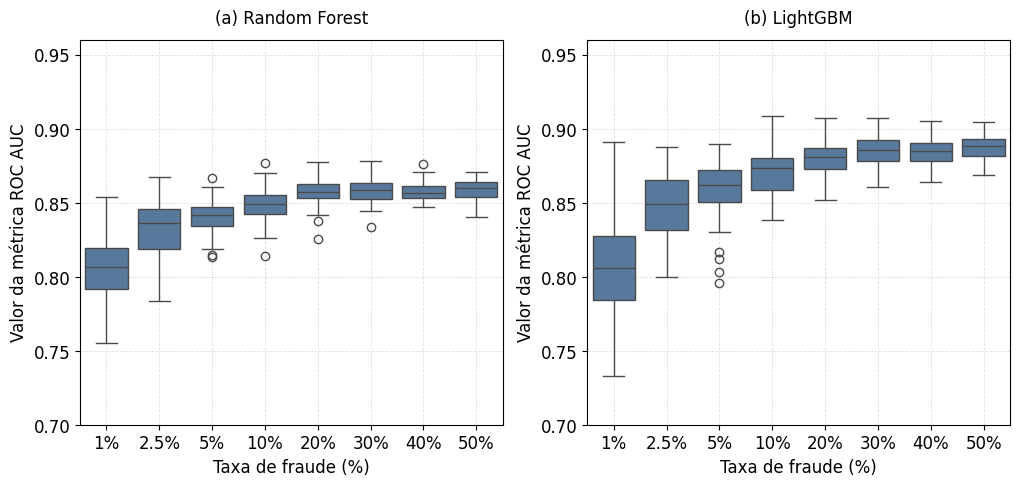

In [33]:
# Restaurar configurações padrão do Seaborn
sns.reset_defaults()

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# Primeiro gráfico
sns.boxplot(data=df_metrics_rf, x="target_rate", y="auc", ax=axes[0], color="#4E79A7")

# Segundo gráfico
sns.boxplot(data=df_metrics_lgbm, x="target_rate", y="auc", ax=axes[1], color="#4E79A7")

# Configuração axes
valores = sorted(df_metrics_rf["target_rate"].unique())

for ax in axes:
    ax.set_xticks(range(len(valores)))
    ax.set_xticklabels([f"{x * 100:g}%" for x in valores])
    ax.set_ylim(0.7, 0.96)
    ax.set_xlabel("Taxa de fraude (%)")
    ax.set_ylabel("Valor da métrica ROC AUC")
    ax.grid(True, which="major", axis="both", linestyle="--", linewidth=0.6, color="#D3D3D3", alpha=0.7)

axes[0].set_title("(a) Random Forest", fontsize=12, fontweight="normal", pad=12)
axes[1].set_title("(b) LightGBM", fontsize=12, fontweight="normal", pad=12)

plt.show()

#### `9.1.2 Kolmogorov-Smirnov`

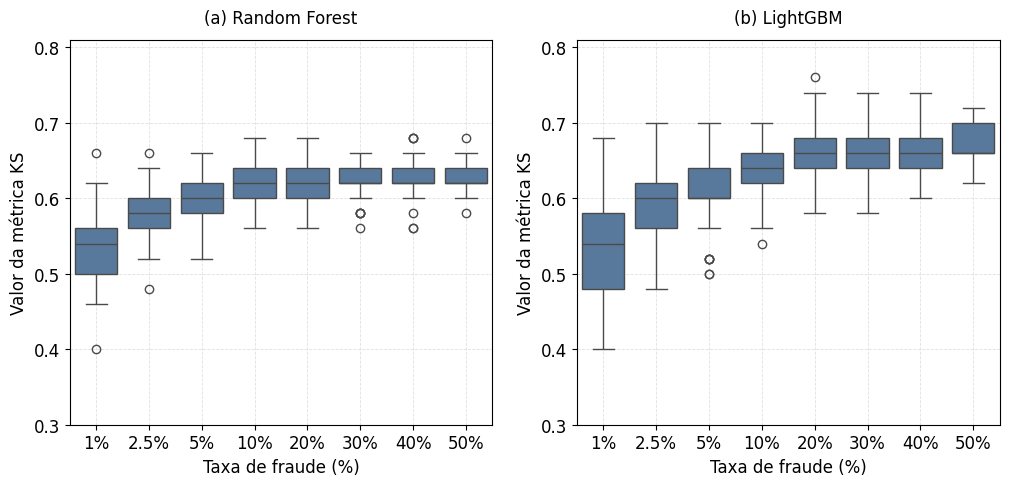

In [34]:
# Restaurar configurações padrão do Seaborn
sns.reset_defaults()

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# Primeiro gráfico
sns.boxplot(data=df_metrics_rf, x="target_rate", y="ks", ax=axes[0], color="#4E79A7")

# Segundo gráfico
sns.boxplot(data=df_metrics_lgbm, x="target_rate", y="ks", ax=axes[1], color="#4E79A7")

# Configuração axes
valores = sorted(df_metrics_rf["target_rate"].unique())

for ax in axes:
    ax.set_xticks(range(len(valores)))
    ax.set_xticklabels([f"{x * 100:g}%" for x in valores])
    ax.set_ylim(0.3, 0.81)
    ax.set_xlabel("Taxa de fraude (%)")
    ax.set_ylabel("Valor da métrica KS")
    ax.grid(True, which="major", axis="both", linestyle="--", linewidth=0.6, color="#D3D3D3", alpha=0.7)

axes[0].set_title("(a) Random Forest", fontsize=12, fontweight="normal", pad=12)
axes[1].set_title("(b) LightGBM", fontsize=12, fontweight="normal", pad=12)

plt.show()

### `9.2 Sequential Rank Agreement - SRA`

#### `9.2.1 SHAP`

In [35]:
df_shap_rf_sra_plot = (
    df_shap_rf_sra
    .groupby(["target_rate", "depth"], as_index=False)
    .agg(sra_mean=("sra", "mean"))
    .sort_values(["target_rate", "depth"])
)

df_shap_lgbm_sra_plot = (
    df_shap_lgbm_sra
    .groupby(["target_rate", "depth"], as_index=False)
    .agg(sra_mean=("sra", "mean"))
    .sort_values(["target_rate", "depth"])
)

In [36]:
df_shap_rf_sra_plot["depth"] = pd.Categorical(df_shap_rf_sra_plot["depth"], categories=[1, 2, 3, 5, 10], ordered=True)
df_shap_rf_sra_plot["target_rate"] = pd.Categorical(df_shap_rf_sra_plot["target_rate"], categories=sorted(df_shap_rf_sra_plot["target_rate"].unique()), ordered=True)

df_shap_lgbm_sra_plot["depth"] = pd.Categorical(df_shap_lgbm_sra_plot["depth"], categories=[1, 2, 3, 5, 10], ordered=True)
df_shap_lgbm_sra_plot["target_rate"] = pd.Categorical(df_shap_lgbm_sra_plot["target_rate"], categories=sorted(df_shap_lgbm_sra_plot["target_rate"].unique()), ordered=True)

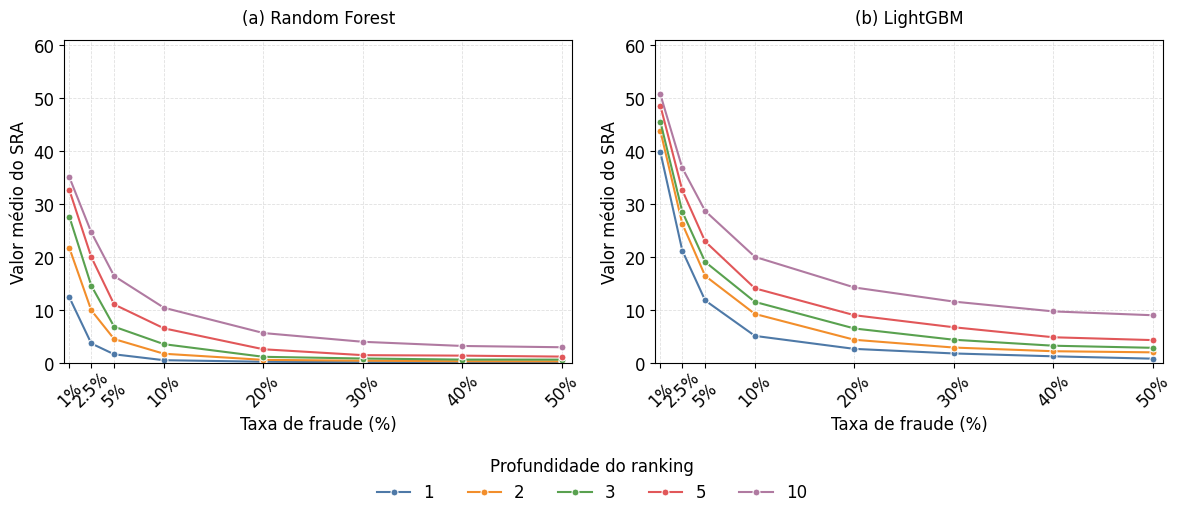

In [37]:
# Restaurar configurações padrão do Seaborn
sns.reset_defaults()

valores = sorted(df_shap_rf_sra_plot["target_rate"].unique())
# Posições personalizadas
posicoes = np.array([0.5, 2.7, 5, 10, 20, 30, 40, 50])
# Criar coluna para o gráfico
mapa = dict(zip(valores, posicoes))

df_shap_rf_sra_plot["x_plot"] = df_shap_rf_sra_plot["target_rate"].map(mapa)
df_shap_lgbm_sra_plot["x_plot"] = df_shap_lgbm_sra_plot["target_rate"].map(mapa)

# Cores
cores = {
    1: "#4E79A7",
    2: "#F28E2B",
    3: "#59A14F",
    5: "#E15759",
    10: "#B07AA1"
}

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# Primeiro gráfico
sns.lineplot(
    data=df_shap_rf_sra_plot,
    x="x_plot",
    y="sra_mean",
    hue="depth",
    hue_order=[1, 2, 3, 5, 10],
    marker="o",
    markersize=5,
    palette=cores,
    ax=axes[0]
)

# Segundo gráfico
sns.lineplot(
    data=df_shap_lgbm_sra_plot,
    x="x_plot",
    y="sra_mean",
    hue="depth",
    hue_order=[1, 2, 3, 5, 10],
    marker="o",
    markersize=5,
    palette=cores,
    ax=axes[1]
)

for ax in axes:
    ax.set_xticks(posicoes)
    ax.set_xticklabels([f"{v *100:g}%" for v in valores], rotation=45, ha="center", va="bottom", rotation_mode="default")
    ax.set_xlim(0, 51)
    ax.set_ylim(0, 61)
    ax.tick_params(axis="x", pad=30)
    ax.set_xlabel("Taxa de fraude (%)")
    ax.set_ylabel("Valor médio do SRA")
    ax.grid(True, which="major", axis="both", linestyle="--", linewidth=0.6, color="#D3D3D3", alpha=0.7)

axes[0].set_title("(a) Random Forest", fontsize=12, fontweight="normal", pad=12)
axes[1].set_title("(b) LightGBM", fontsize=12, fontweight="normal", pad=12)

# Remover legendas individuais
for ax in axes:
    if ax.get_legend():
        ax.get_legend().remove()

# Legenda compartilhada
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Profundidade do ranking",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=5,
    frameon=False
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.show()

#### `9.2.2 LIME`

In [38]:
df_lime_rf_sra_plot = (
    df_lime_rf_sra
    .groupby(["target_rate", "depth"], as_index=False)
    .agg(sra_mean=("sra", "mean"))
    .sort_values(["target_rate", "depth"])
)

df_lime_lgbm_sra_plot = (
    df_lime_lgbm_sra
    .groupby(["target_rate", "depth"], as_index=False)
    .agg(sra_mean=("sra", "mean"))
    .sort_values(["target_rate", "depth"])
)

In [39]:
df_lime_rf_sra_plot["depth"] = pd.Categorical(df_lime_rf_sra_plot["depth"], categories=[1, 2, 3, 5, 10], ordered=True)
df_lime_rf_sra_plot["target_rate"] = pd.Categorical(df_lime_rf_sra_plot["target_rate"], categories=sorted(df_lime_rf_sra_plot["target_rate"].unique()), ordered=True)

df_lime_lgbm_sra_plot["depth"] = pd.Categorical(df_lime_lgbm_sra_plot["depth"], categories=[1, 2, 3, 5, 10], ordered=True)
df_lime_lgbm_sra_plot["target_rate"] = pd.Categorical(df_lime_lgbm_sra_plot["target_rate"], categories=sorted(df_lime_lgbm_sra_plot["target_rate"].unique()), ordered=True)

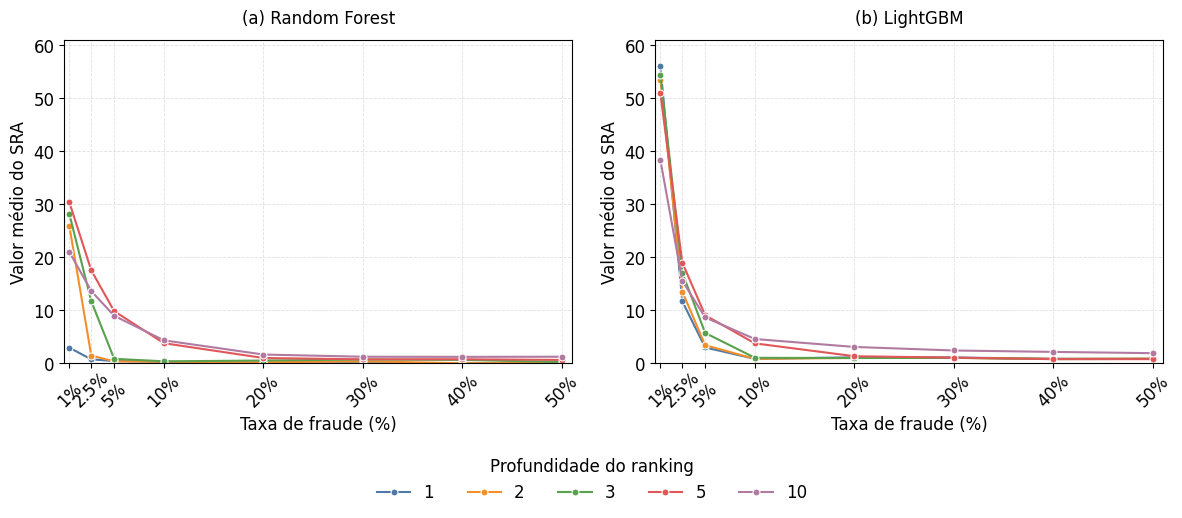

In [40]:
# Restaurar configurações padrão do Seaborn
sns.reset_defaults()

valores = sorted(df_lime_rf_sra_plot["target_rate"].unique())
# Posições personalizadas
posicoes = np.array([0.5, 2.7, 5, 10, 20, 30, 40, 50])
# Criar coluna para o gráfico
mapa = dict(zip(valores, posicoes))

df_lime_rf_sra_plot["x_plot"] = df_lime_rf_sra_plot["target_rate"].map(mapa)
df_lime_lgbm_sra_plot["x_plot"] = df_lime_lgbm_sra_plot["target_rate"].map(mapa)

# Cores
cores = {
    1: "#4E79A7",
    2: "#F28E2B",
    3: "#59A14F",
    5: "#E15759",
    10: "#B07AA1"
}

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# Primeiro gráfico
sns.lineplot(
    data=df_lime_rf_sra_plot,
    x="x_plot",
    y="sra_mean",
    hue="depth",
    hue_order=[1, 2, 3, 5, 10],
    marker="o",
    markersize=5,
    palette=cores,
    ax=axes[0]
)

# Segundo gráfico
sns.lineplot(
    data=df_lime_lgbm_sra_plot,
    x="x_plot",
    y="sra_mean",
    hue="depth",
    hue_order=[1, 2, 3, 5, 10],
    marker="o",
    markersize=5,
    palette=cores,
    ax=axes[1]
)

for ax in axes:
    ax.set_xticks(posicoes)
    ax.set_xticklabels([f"{v *100:g}%" for v in valores], rotation=45, ha="center", va="bottom", rotation_mode="default")
    ax.set_xlim(0, 51)
    ax.set_ylim(0, 61)
    ax.tick_params(axis="x", pad=30)
    ax.set_xlabel("Taxa de fraude (%)")
    ax.set_ylabel("Valor médio do SRA")
    ax.grid(True, which="major", axis="both", linestyle="--", linewidth=0.6, color="#D3D3D3", alpha=0.7)

axes[0].set_title("(a) Random Forest", fontsize=12, fontweight="normal", pad=12)
axes[1].set_title("(b) LightGBM", fontsize=12, fontweight="normal", pad=12)

# Remover legendas individuais
for ax in axes:
    if ax.get_legend():
        ax.get_legend().remove()

# Legenda compartilhada
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Profundidade do ranking",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=5,
    frameon=False
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.show()

### `9.3 Coeficiente de Similaridade de Jaccard`

#### `9.3.1 SHAP`

In [44]:
df_shap_rf_jaccard_plot = (
    df_shap_rf_jaccard
    .groupby(["target_rate", "depth"], as_index=False)
    .agg(jaccard_mean=("jaccard", "mean"))
    .sort_values(["target_rate", "depth"])
)

df_shap_lgbm_jaccard_plot = (
    df_shap_lgbm_jaccard
    .groupby(["target_rate", "depth"], as_index=False)
    .agg(jaccard_mean=("jaccard", "mean"))
    .sort_values(["target_rate", "depth"])
)

In [45]:
df_shap_rf_jaccard_plot["depth"] = pd.Categorical(df_shap_rf_jaccard_plot["depth"], categories=[1, 2, 3, 5, 10], ordered=True)
df_shap_rf_jaccard_plot["target_rate"] = pd.Categorical(df_shap_rf_jaccard_plot["target_rate"], categories=sorted(df_shap_rf_jaccard_plot["target_rate"].unique()), ordered=True)

df_shap_lgbm_jaccard_plot["depth"] = pd.Categorical(df_shap_lgbm_jaccard_plot["depth"], categories=[1, 2, 3, 5, 10], ordered=True)
df_shap_lgbm_jaccard_plot["target_rate"] = pd.Categorical(df_shap_lgbm_jaccard_plot["target_rate"], categories=sorted(df_shap_lgbm_jaccard_plot["target_rate"].unique()), ordered=True)

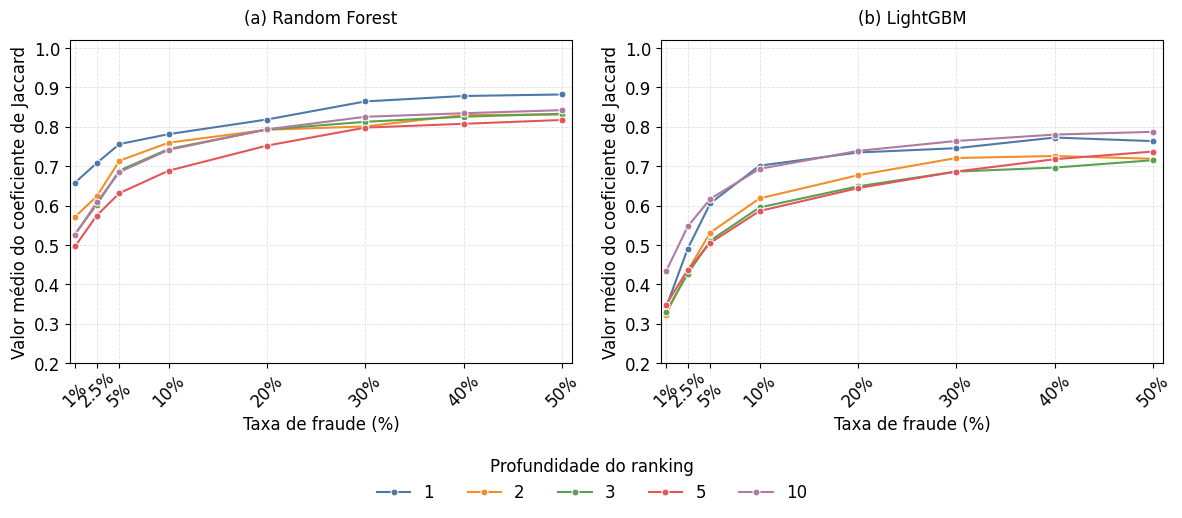

In [46]:
# Restaurar configurações padrão do Seaborn
sns.reset_defaults()

valores = sorted(df_shap_rf_jaccard_plot["target_rate"].unique())
# Posições personalizadas
posicoes = np.array([0.5, 2.7, 5, 10, 20, 30, 40, 50])
# Criar coluna para o gráfico
mapa = dict(zip(valores, posicoes))

df_shap_rf_jaccard_plot["x_plot"] = df_shap_rf_jaccard_plot["target_rate"].map(mapa)
df_shap_lgbm_jaccard_plot["x_plot"] = df_shap_lgbm_jaccard_plot["target_rate"].map(mapa)

# Cores
cores = {
    1: "#4E79A7",
    2: "#F28E2B",
    3: "#59A14F",
    5: "#E15759",
    10: "#B07AA1"
}

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# Primeiro gráfico
sns.lineplot(
    data=df_shap_rf_jaccard_plot,
    x="x_plot",
    y="jaccard_mean",
    hue="depth",
    hue_order=[1, 2, 3, 5, 10],
    marker="o",
    markersize=5,
    palette=cores,
    ax=axes[0]
)

# Segundo gráfico
sns.lineplot(
    data=df_shap_lgbm_jaccard_plot,
    x="x_plot",
    y="jaccard_mean",
    hue="depth",
    hue_order=[1, 2, 3, 5, 10],
    marker="o",
    markersize=5,
    palette=cores,
    ax=axes[1]
)

for ax in axes:
    ax.set_xticks(posicoes)
    ax.set_xticklabels([f"{v *100:g}%" for v in valores], rotation=45, ha="center", va="bottom", rotation_mode="default")
    ax.set_xlim(0, 51)
    ax.set_ylim(0.2, 1.02)
    ax.tick_params(axis="x", pad=30)
    ax.set_xlabel("Taxa de fraude (%)")
    ax.set_ylabel("Valor médio do coeficiente de Jaccard")
    ax.grid(True, which="major", axis="both", linestyle="--", linewidth=0.6, color="#D3D3D3", alpha=0.7)

axes[0].set_title("(a) Random Forest", fontsize=12, fontweight="normal", pad=12)
axes[1].set_title("(b) LightGBM", fontsize=12, fontweight="normal", pad=12)

# Remover legendas individuais
for ax in axes:
    if ax.get_legend():
        ax.get_legend().remove()

# Legenda compartilhada
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Profundidade do ranking",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=5,
    frameon=False
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.show()

#### `9.3.2 LIME`

In [47]:
df_lime_rf_jaccard_plot = (
    df_lime_rf_jaccard
    .groupby(["target_rate", "depth"], as_index=False)
    .agg(jaccard_mean=("jaccard", "mean"))
    .sort_values(["target_rate", "depth"])
)

df_lime_lgbm_jaccard_plot = (
    df_lime_lgbm_jaccard
    .groupby(["target_rate", "depth"], as_index=False)
    .agg(jaccard_mean=("jaccard", "mean"))
    .sort_values(["target_rate", "depth"])
)

In [48]:
df_lime_rf_jaccard_plot["depth"] = pd.Categorical(df_lime_rf_jaccard_plot["depth"], categories=[1, 2, 3, 5, 10], ordered=True)
df_lime_rf_jaccard_plot["target_rate"] = pd.Categorical(df_lime_rf_jaccard_plot["target_rate"], categories=sorted(df_lime_rf_jaccard_plot["target_rate"].unique()), ordered=True)

df_lime_lgbm_jaccard_plot["depth"] = pd.Categorical(df_lime_lgbm_jaccard_plot["depth"], categories=[1, 2, 3, 5, 10], ordered=True)
df_lime_lgbm_jaccard_plot["target_rate"] = pd.Categorical(df_lime_lgbm_jaccard_plot["target_rate"], categories=sorted(df_lime_lgbm_jaccard_plot["target_rate"].unique()), ordered=True)

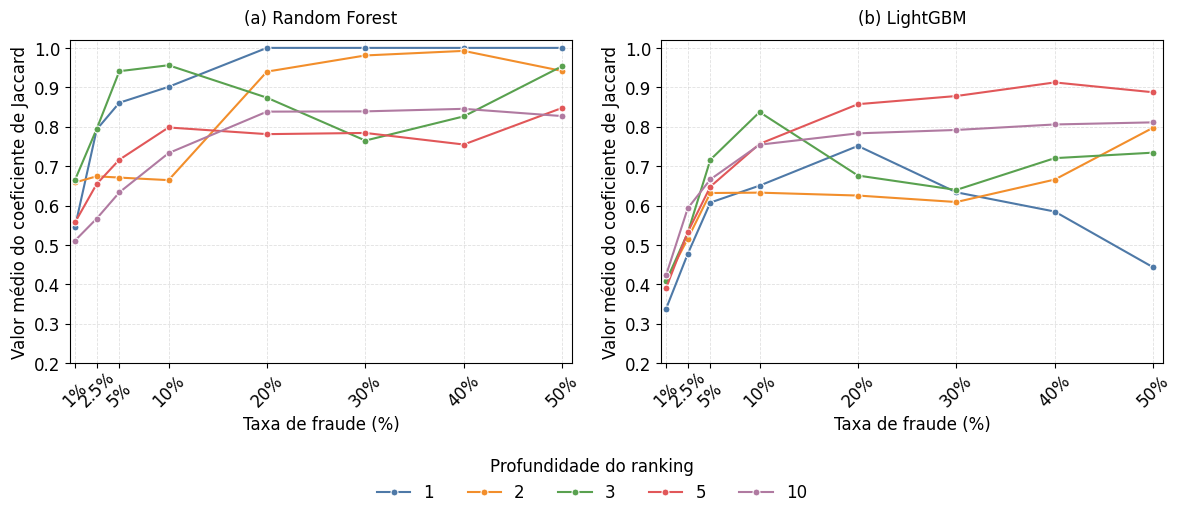

In [49]:
# Restaurar configurações padrão do Seaborn
sns.reset_defaults()

valores = sorted(df_lime_rf_jaccard_plot["target_rate"].unique())
# Posições personalizadas
posicoes = np.array([0.5, 2.7, 5, 10, 20, 30, 40, 50])
# Criar coluna para o gráfico
mapa = dict(zip(valores, posicoes))

df_lime_rf_jaccard_plot["x_plot"] = df_lime_rf_jaccard_plot["target_rate"].map(mapa)
df_lime_lgbm_jaccard_plot["x_plot"] = df_lime_lgbm_jaccard_plot["target_rate"].map(mapa)

# Cores
cores = {
    1: "#4E79A7",
    2: "#F28E2B",
    3: "#59A14F",
    5: "#E15759",
    10: "#B07AA1"
}

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# Primeiro gráfico
sns.lineplot(
    data=df_lime_rf_jaccard_plot,
    x="x_plot",
    y="jaccard_mean",
    hue="depth",
    hue_order=[1, 2, 3, 5, 10],
    marker="o",
    markersize=5,
    palette=cores,
    ax=axes[0]
)

# Segundo gráfico
sns.lineplot(
    data=df_lime_lgbm_jaccard_plot,
    x="x_plot",
    y="jaccard_mean",
    hue="depth",
    hue_order=[1, 2, 3, 5, 10],
    marker="o",
    markersize=5,
    palette=cores,
    ax=axes[1]
)

for ax in axes:
    ax.set_xticks(posicoes)
    ax.set_xticklabels([f"{v *100:g}%" for v in valores], rotation=45, ha="center", va="bottom", rotation_mode="default")
    ax.set_xlim(0, 51)
    ax.set_ylim(0.2, 1.02)
    ax.tick_params(axis="x", pad=30)
    ax.set_xlabel("Taxa de fraude (%)")
    ax.set_ylabel("Valor médio do coeficiente de Jaccard")
    ax.grid(True, which="major", axis="both", linestyle="--", linewidth=0.6, color="#D3D3D3", alpha=0.7)

axes[0].set_title("(a) Random Forest", fontsize=12, fontweight="normal", pad=12)
axes[1].set_title("(b) LightGBM", fontsize=12, fontweight="normal", pad=12)

# Remover legendas individuais
for ax in axes:
    if ax.get_legend():
        ax.get_legend().remove()

# Legenda compartilhada
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Profundidade do ranking",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=5,
    frameon=False
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.show()

### `9.4 Coefficient of Variation (CV)`

#### `9.4.1 SHAP`

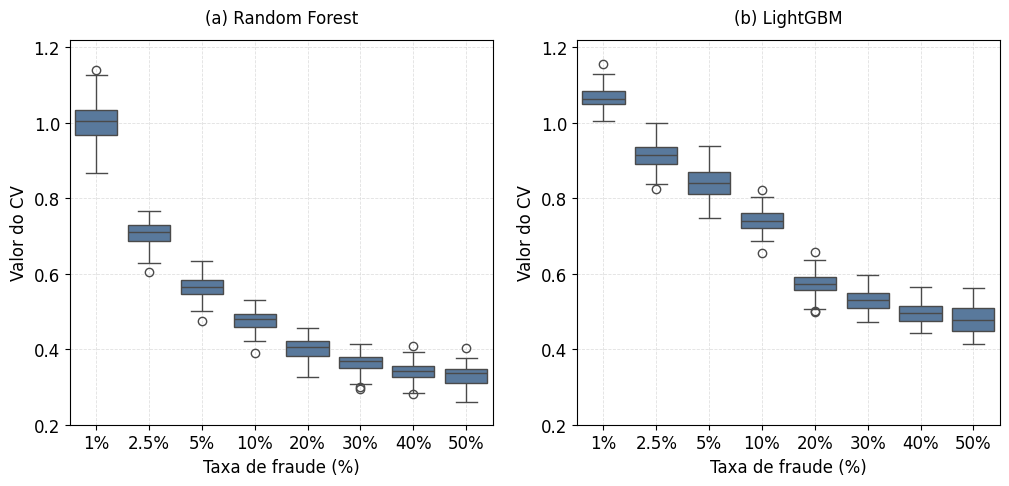

In [62]:
# Restaurar configurações padrão do Seaborn
sns.reset_defaults()

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# Primeiro gráfico
sns.boxplot(data=df_shap_rf_cv, x="target_rate", y="cv", ax=axes[0], color="#4E79A7")

# Segundo gráfico
sns.boxplot(data=df_shap_lgbm_cv, x="target_rate", y="cv", ax=axes[1], color="#4E79A7")

# Configuração axes
valores = sorted(df_shap_rf_cv["target_rate"].unique())

for ax in axes:
    ax.set_xticks(range(len(valores)))
    ax.set_xticklabels([f"{x * 100:g}%" for x in valores])
    ax.set_ylim(0.2, 1.22)
    ax.set_xlabel("Taxa de fraude (%)")
    ax.set_ylabel("Valor do CV")
    ax.grid(True, which="major", axis="both", linestyle="--", linewidth=0.6, color="#D3D3D3", alpha=0.7)

axes[0].set_title("(a) Random Forest", fontsize=12, fontweight="normal", pad=12)
axes[1].set_title("(b) LightGBM", fontsize=12, fontweight="normal", pad=12)

plt.show()

#### `9.4.2 LIME`

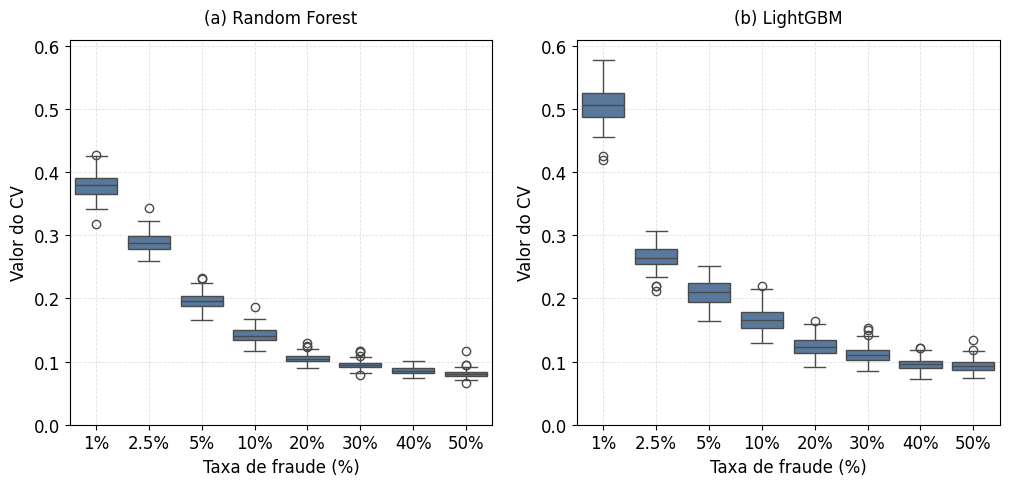

In [64]:
# Restaurar configurações padrão do Seaborn
sns.reset_defaults()

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# Primeiro gráfico
sns.boxplot(data=df_lime_rf_cv, x="target_rate", y="cv", ax=axes[0], color="#4E79A7")

# Segundo gráfico
sns.boxplot(data=df_lime_lgbm_cv, x="target_rate", y="cv", ax=axes[1], color="#4E79A7")

# Configuração axes
valores = sorted(df_lime_rf_cv["target_rate"].unique())

for ax in axes:
    ax.set_xticks(range(len(valores)))
    ax.set_xticklabels([f"{x * 100:g}%" for x in valores])
    ax.set_ylim(0.0, 0.61)
    ax.set_xlabel("Taxa de fraude (%)")
    ax.set_ylabel("Valor do CV")
    ax.grid(True, which="major", axis="both", linestyle="--", linewidth=0.6, color="#D3D3D3", alpha=0.7)

axes[0].set_title("(a) Random Forest", fontsize=12, fontweight="normal", pad=12)
axes[1].set_title("(b) LightGBM", fontsize=12, fontweight="normal", pad=12)

plt.show()

### `9.5 VSI`

0 Axes(0.125,0.53;0.352273x0.35)
1 Axes(0.547727,0.53;0.352273x0.35)
2 Axes(0.125,0.11;0.352273x0.35)
3 Axes(0.547727,0.11;0.352273x0.35)


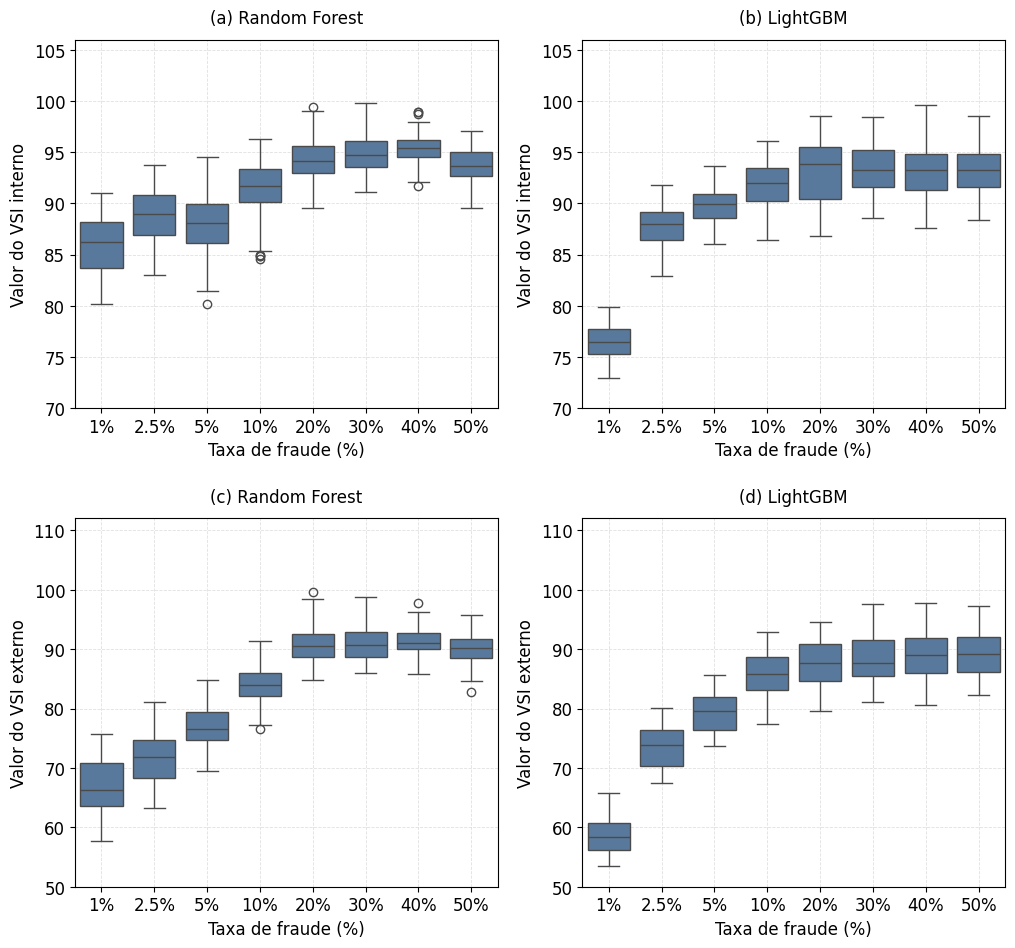

In [67]:
# Restaurar configurações padrão do Seaborn
sns.reset_defaults()

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12
})

fig, axes = plt.subplots(2, 2, figsize=(12, 11), sharey=False)

# Primeiro gráfico
sns.boxplot(data=df_lime_internal_rf_indices, x="target_rate", y="vsi_internal", ax=axes[0, 0], color="#4E79A7")

# Segundo gráfico
sns.boxplot(data=df_lime_internal_lgbm_indices, x="target_rate", y="vsi_internal", ax=axes[0, 1], color="#4E79A7")

# Terceiro gráfico
sns.boxplot(data=df_lime_external_rf_indices, x="target_rate", y="vsi_external", ax=axes[1, 0], color="#4E79A7")

# Quarto gráfico
sns.boxplot(data=df_lime_external_lgbm_indices, x="target_rate", y="vsi_external", ax=axes[1, 1], color="#4E79A7")

# Configuração axes
valores = sorted(df_lime_internal_rf_indices["target_rate"].unique())

for i, ax in enumerate(axes.flat):
    print(i, ax)
    ax.set_xticks(range(len(valores)))
    ax.set_xticklabels([f"{x * 100:g}%" for x in valores])

    if i < 2:
        ax.set_ylim(70, 106)
    else:
        ax.set_ylim(50, 112)

    ax.set_xlabel("Taxa de fraude (%)")
    ax.set_ylabel("Valor do VSI interno" if i < 2 else "Valor do VSI externo")
    ax.grid(True, which="major", axis="both", linestyle="--", linewidth=0.6, color="#D3D3D3", alpha=0.7)

# Títulos dos subgráficos
axes[0, 0].set_title("(a) Random Forest", fontsize=12, fontweight="normal", pad=12)
axes[0, 1].set_title("(b) LightGBM", fontsize=12, fontweight="normal", pad=12)
axes[1, 0].set_title("(c) Random Forest", fontsize=12, fontweight="normal", pad=12)
axes[1, 1].set_title("(d) LightGBM", fontsize=12, fontweight="normal", pad=12)

plt.subplots_adjust(hspace=0.3)

plt.show()

### `9.6 CSI`

0 Axes(0.125,0.53;0.352273x0.35)
1 Axes(0.547727,0.53;0.352273x0.35)
2 Axes(0.125,0.11;0.352273x0.35)
3 Axes(0.547727,0.11;0.352273x0.35)


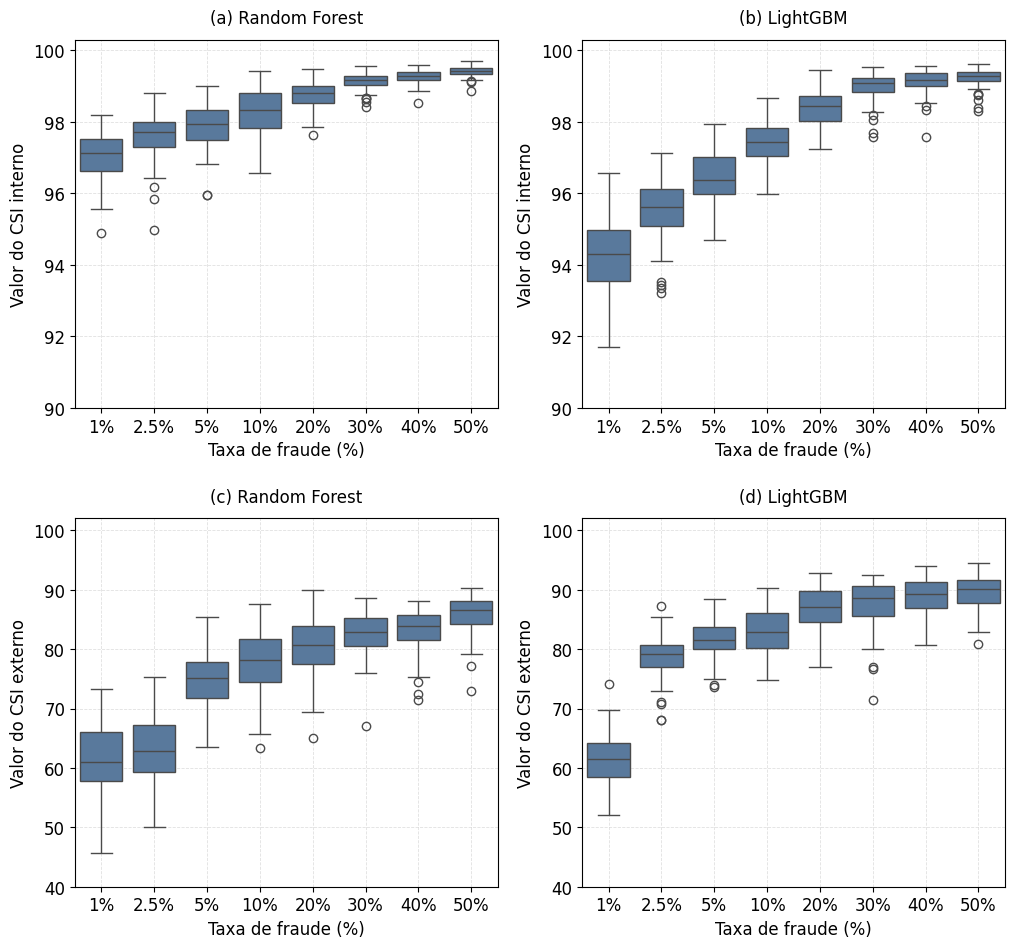

In [72]:
# Restaurar configurações padrão do Seaborn
sns.reset_defaults()

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12
})

fig, axes = plt.subplots(2, 2, figsize=(12, 11), sharey=False)

# Primeiro gráfico
sns.boxplot(data=df_lime_internal_rf_indices, x="target_rate", y="csi_internal", ax=axes[0, 0], color="#4E79A7")

# Segundo gráfico
sns.boxplot(data=df_lime_internal_lgbm_indices, x="target_rate", y="csi_internal", ax=axes[0, 1], color="#4E79A7")

# Terceiro gráfico
sns.boxplot(data=df_lime_external_rf_indices, x="target_rate", y="csi_external", ax=axes[1, 0], color="#4E79A7")

# Quarto gráfico
sns.boxplot(data=df_lime_external_lgbm_indices, x="target_rate", y="csi_external", ax=axes[1, 1], color="#4E79A7")

# Configuração axes
valores = sorted(df_lime_internal_rf_indices["target_rate"].unique())

for i, ax in enumerate(axes.flat):
    print(i, ax)
    ax.set_xticks(range(len(valores)))
    ax.set_xticklabels([f"{x * 100:g}%" for x in valores])

    if i < 2:
        ax.set_ylim(90, 100.3)
    else:
        ax.set_ylim(40, 102)

    ax.set_xlabel("Taxa de fraude (%)")
    ax.set_ylabel("Valor do CSI interno" if i < 2 else "Valor do CSI externo")
    ax.grid(True, which="major", axis="both", linestyle="--", linewidth=0.6, color="#D3D3D3", alpha=0.7)

# Títulos dos subgráficos
axes[0, 0].set_title("(a) Random Forest", fontsize=12, fontweight="normal", pad=12)
axes[0, 1].set_title("(b) LightGBM", fontsize=12, fontweight="normal", pad=12)
axes[1, 0].set_title("(c) Random Forest", fontsize=12, fontweight="normal", pad=12)
axes[1, 1].set_title("(d) LightGBM", fontsize=12, fontweight="normal", pad=12)

plt.subplots_adjust(hspace=0.3)

plt.show()